# Bangla News Summarization (BanglaT5 + XL-Sum)

**Goal:** Fine-tune the BanglaT5 model so it can read a Bangla news article and write a short summary.

**Data:** XL-Sum (Bengali): news articles with human-written summaries.
**Model:** `csebuetnlp/banglat5` (already pre-trained on Bangla text).
**Hardware:** Kaggle GPU (T4).

In [1]:
!pip install -q transformers "datasets<4.0" accelerate sentencepiece
!pip install -q git+https://github.com/csebuetnlp/normalizer
!pip install -q pyonmttok git+https://github.com/abhik1505040/bengali-stemmer
!pip install -q "git+https://github.com/csebuetnlp/xl-sum.git#subdirectory=multilingual_rouge_scoring"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 7.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 5.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 4.5 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.7/17.7 MB 93.0 MB/s eta 0:00:00:00:0100:01
  Preparing metadata (setup.py) ... done


In [2]:
import numpy as np
import torch
import datasets
import transformers
from collections import Counter
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer, EarlyStoppingCallback
from normalizer import normalize
import time
import regex
from bengali_stemmer.rafikamal2014 import RafiStemmer
from rouge_score import rouge_scorer

print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
assert datasets.__version__.startswith("3."), "Wrong datasets version: run 1.1, then Run -> Restart session"
assert torch.cuda.is_available(), "GPU is off: turn on the GPU in the notebook settings"
print("GPU:", torch.cuda.get_device_name(0))

transformers: 5.0.0
datasets: 3.6.0
GPU: Tesla T4


## 2. Data

### 2.1 Load the dataset

**What:** Download the Bengali part of XL-Sum from the Hugging Face Hub.
**Why:** This is the data the model will learn from. It has three parts:
- `train`: the model learns from it
- `validation`: checked during training
- `test`: used at the end, on data the model has not seen

`trust_remote_code=True` lets `datasets` run the dataset's own loading script (`xlsum.py`).

In [3]:
ds = load_dataset("csebuetnlp/xlsum", "bengali", trust_remote_code=True)
print(ds)

README.md: 0.00B [00:00, ?B/s]

xlsum.py: 0.00B [00:00, ?B/s]

data/bengali_XLSum_v2.0.tar.bz2:   0%|          | 0.00/13.0M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8102
    })
    test: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 1012
    })
    validation: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 1012
    })
})


### 2.2 Look at one example

In [4]:
example = ds["train"][0]

print("TITLE:", example["title"])
print()
print("SUMMARY:", example["summary"])
print()
print("TEXT (first 500 characters):")
print(example["text"][:500])

TITLE: দুর্গাপূজার সময়ে যেভাবে শোক পালন করেন 'মহিষাসুরের বংশধরেরা'

SUMMARY: হিন্দু বাঙালীরা যে সময়ে তাদের সবথেকে বড় উৎসব দুর্গাপূজা উদযাপন করেন, সেই সময়েই শোক পালন করেন অসুর বংশীয় আদিবাসীরা।

TEXT (first 500 characters):
দুর্গাপুজায় মহিষাসুর বধ্যে মধ্য দিয়ে অশুভর ওপর শুভর বিজয় দেখানো হয়। কিন্তু সেটা বিজয়ীর লেখা ইতিহাস বলেই গবেষকরা এখন বলছেন। তাদের লোককথা অনুযায়ী, আর্যদের দেবী দুর্গা এই সময়েই তাদের রাজা মহিষাসুরকে ছলনার মাধ্যমে হত্যা করেছিলেন। রাজাকে হারানোর শোক হাজার হাজার বছর ধরেও ভুলতে পারেননি আদিবাসী সমাজ। 'অসুর' ভারতের একটি বিশেষ আদিবাসী উপজাতি। পশ্চিমবঙ্গ, ঝাড়খণ্ড আর বিহার - এই তিন রাজ্যের সরকারি তপশিলী উপজাতিদের তালিকার একেবারে প্রথম নামটিই হল অসুর। তবে এখন 'অসুর' ছাড়া অন্য আদিবাসী সমাজও মহিষাসুর 


### 2.3 How long are the articles and summaries? (in words)

In [5]:
sample = ds["train"].shuffle(seed=42).select(range(1000))

text_words = [len(x["text"].split()) for x in sample]
summary_words = [len(x["summary"].split()) for x in sample]

print("Article words -> median:", int(np.median(text_words)), "| max:", max(text_words))
print("Summary words -> median:", int(np.median(summary_words)), "| max:", max(summary_words))

Article words -> median: 533 | max: 3334
Summary words -> median: 21 | max: 76


### 2.4 Cross-check: all training rows

**What:** Count words for all 8102 training rows, not just a sample.
**Why:** The sample in 2.3 is an estimate. This checks that it is close to the full data. (Using 1000 rows gave a very different result, so the first rows are not representative of the whole data.)

In [6]:
all_text_words = [len(x["text"].split()) for x in ds["train"]]
all_summary_words = [len(x["summary"].split()) for x in ds["train"]]

print("Rows counted:", len(all_text_words))
print("Article words -> median:", int(np.median(all_text_words)), "| max:", max(all_text_words))
print("Summary words -> median:", int(np.median(all_summary_words)), "| max:", max(all_summary_words))

Rows counted: 8102
Article words -> median: 525 | max: 3726
Summary words -> median: 22 | max: 119


## 3. Tokenizer

### 3.1 Load the tokenizer and see how a sentence is split

**What:** Load the BanglaT5 tokenizer and split one summary into tokens.
**Why:** The model does not read words. It reads tokens (pieces of words) as numbers. One word can become more than one token, so token counts are larger than word counts. The mark `▁` shows where a new word starts.

`use_fast=False` follows the BanglaT5 model card.

In [7]:
tok = AutoTokenizer.from_pretrained("csebuetnlp/banglat5", use_fast=False)

sentence = ds["train"][0]["summary"]
tokens = tok.tokenize(sentence)

print("Words :", len(sentence.split()))
print("Tokens:", len(tokens))
print(tokens)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Words : 19
Tokens: 24
['▁হিন্দু', '▁বাঙালী', 'রা', '▁যে', '▁সময়ে', '▁তাদের', '▁সবথেকে', '▁বড়', '▁উৎসব', '▁দুর্গাপূজা', '▁উদযাপন', '▁করেন', ',', '▁সেই', '▁সময়েই', '▁শোক', '▁পালন', '▁করেন', '▁অসুর', '▁বংশী', 'য়', '▁আদিবাসী', 'রা', '।']


### 3.2a Normalizer: clean the text

**What:** Clean Bangla text with `normalize()` and count how many of 200 articles change.
**Why:** BanglaT5 was pre-trained on text cleaned this way, and its model card says to normalize text before tokenizing. The same cleaning must be used in training and in the final demo.

In [8]:
raw = ds["train"][0]["summary"]
clean = normalize(raw)

print("Same text?", raw == clean)
print("RAW  :", raw)
print("CLEAN:", clean)

changed = 0
for x in sample.select(range(200)):
    if normalize(x["text"]) != x["text"]:
        changed += 1
print("Articles changed by normalizer:", changed, "out of 200")

Same text? True
RAW  : হিন্দু বাঙালীরা যে সময়ে তাদের সবথেকে বড় উৎসব দুর্গাপূজা উদযাপন করেন, সেই সময়েই শোক পালন করেন অসুর বংশীয় আদিবাসীরা।
CLEAN: হিন্দু বাঙালীরা যে সময়ে তাদের সবথেকে বড় উৎসব দুর্গাপূজা উদযাপন করেন, সেই সময়েই শোক পালন করেন অসুর বংশীয় আদিবাসীরা।
Articles changed by normalizer: 23 out of 200


### 3.2b What exactly did the normalizer change?

**What:** For the changed articles among the first 200 sample rows, list which characters disappeared and which appeared.
**Why:** `normalize()` does several kinds of cleaning. This shows which kinds really happen in our data.

In [9]:
disappeared = Counter()
appeared = Counter()

for x in sample.select(range(200)):
    original = x["text"]
    cleaned = normalize(original)
    if cleaned != original:
        disappeared.update(Counter(original) - Counter(cleaned))
        appeared.update(Counter(cleaned) - Counter(original))

print("Characters that disappeared:")
for ch, n in disappeared.most_common(8):
    print("  ", repr(ch), hex(ord(ch)), n)

print("Characters that appeared:")
for ch, n in appeared.most_common(8):
    print("  ", repr(ch), hex(ord(ch)), n)

Characters that disappeared:
   '“' 0x201c 64
   '‘' 0x2018 37
   '”' 0x201d 27
   '’' 0x2019 25
   '–' 0x2013 22
   '…' 0x2026 2
   '—' 0x2014 1
Characters that appeared:
   '"' 0x22 91
   "'" 0x27 62
   '-' 0x2d 23
   '.' 0x2e 6
   ' ' 0x20 2


### 3.3 Count tokens

**What:** Normalize each text, tokenize it, and count the tokens for the same 1000 sample rows.
**Why:** Model limits are in tokens, not words. These counts show how long the inputs really are for the model.

A warning about "sequence length longer than the maximum" may appear. It is harmless here because we only count, we do not run the model.

In [10]:
text_tokens = [len(tok(normalize(x["text"])).input_ids) for x in sample]
summary_tokens = [len(tok(normalize(x["summary"])).input_ids) for x in sample]

print("Article tokens -> median:", int(np.median(text_tokens)), "| max:", max(text_tokens))
print("Summary tokens -> median:", int(np.median(summary_tokens)), "| max:", max(summary_tokens))

Token indices sequence length is longer than the specified maximum sequence length for this model (1154 > 512). Running this sequence through the model will result in indexing errors


Article tokens -> median: 686 | max: 4294
Summary tokens -> median: 27 | max: 110


### 3.4 How many texts fit in a limit?

**What:** For several possible length limits, compute the percentage of articles and summaries that fit completely.
**Why:** Text longer than the limit is cut off. These percentages help us choose `max_input_length` and `max_target_length`.

In [11]:
text_tokens = np.array(text_tokens)
summary_tokens = np.array(summary_tokens)

for limit in [512, 768, 1024]:
    pct = (text_tokens <= limit).mean() * 100
    print(f"Articles that fit in {limit} tokens: {pct:.1f}%")

for limit in [64, 96, 128]:
    pct = (summary_tokens <= limit).mean() * 100
    print(f"Summaries that fit in {limit} tokens: {pct:.1f}%")

Articles that fit in 512 tokens: 31.5%
Articles that fit in 768 tokens: 58.8%
Articles that fit in 1024 tokens: 78.5%
Summaries that fit in 64 tokens: 98.6%
Summaries that fit in 96 tokens: 99.9%
Summaries that fit in 128 tokens: 100.0%


### 3.5 Choose the length limits

**Decision (working value):** `max_input_length = 1024` and `max_target_length = 96`.

**Why:**
- With 512 tokens only 31.5% of articles fit; with 1024 tokens 78.5% fit. The extra length lets the model see more of each article.
- BanglaT5 is a T5 model with relative position buckets (no fixed position table), so a longer input is allowed.
- 99.9% of summaries fit in 96 tokens.

**To check before the long training run:** memory and time on the T4 GPU. If 1024 is too heavy, fall back to 768 or 512 (the limit the XL-Sum authors used).

These numbers come from 1000 random training rows.

In [12]:
max_input_length = 1024
max_target_length = 96

print("max_input_length :", max_input_length)
print("max_target_length:", max_target_length)

max_input_length : 1024
max_target_length: 96


In [13]:
mt5_tok = AutoTokenizer.from_pretrained("google/mt5-base", use_fast=False)

sentence = ds["train"][0]["summary"]
print("Words          :", len(sentence.split()))
print("BanglaT5 tokens:", len(tok.tokenize(sentence)))
print("mT5 tokens     :", len(mt5_tok.tokenize(sentence)))

mt5_text_tokens = np.array([len(mt5_tok(x["text"]).input_ids) for x in sample])
print("mT5 article tokens -> median:", int(np.median(mt5_text_tokens)))
print(f"Articles that fit in 512 mT5 tokens: {(mt5_text_tokens <= 512).mean() * 100:.1f}%")

config.json:   0%|          | 0.00/702 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

Words          : 19
BanglaT5 tokens: 24
mT5 tokens     : 51
mT5 article tokens -> median: 1416
Articles that fit in 512 mT5 tokens: 5.4%


In [14]:
print("BanglaT5 pieces:", tok.tokenize(sentence))
print()
print("mT5 pieces     :", mt5_tok.tokenize(sentence))

BanglaT5 pieces: ['▁হিন্দু', '▁বাঙালী', 'রা', '▁যে', '▁সময়ে', '▁তাদের', '▁সবথেকে', '▁বড়', '▁উৎসব', '▁দুর্গাপূজা', '▁উদযাপন', '▁করেন', ',', '▁সেই', '▁সময়েই', '▁শোক', '▁পালন', '▁করেন', '▁অসুর', '▁বংশী', 'য়', '▁আদিবাসী', 'রা', '।']

mT5 pieces     : ['▁হি', 'ন্দু', '▁বা', 'ঙ', 'ালী', 'রা', '▁যে', '▁সময়', 'ে', '▁তা', 'দের', '▁', 'সব', 'থে', 'কে', '▁', 'বড়', '▁উ', 'ৎস', 'ব', '▁দুর্', 'গা', 'প', 'ূ', 'জা', '▁উদ', 'যাপ', 'ন', '▁করে', 'ন', ',', '▁সে', 'ই', '▁সময়', 'েই', '▁শো', 'ক', '▁পাল', 'ন', '▁করে', 'ন', '▁অস', 'ুর', '▁ব', 'ংশ', 'ীয়', '▁আ', 'দি', 'বাসী', 'রা', '।']


### Side check (optional): BanglaT5 vs mT5 tokenizer

**What:** Count tokens for the same Bangla text with the mT5 tokenizer (`google/mt5-base`) and compare with the BanglaT5 tokenizer (`tok`).

**Why:** The XL-Sum authors' README example uses mT5 with a 512-token input limit. The same text gives a different token count in each tokenizer, so their 512 is not the same amount of text as our 512.

**What we found:**
- Median article (1000 random training articles): 686 tokens (BanglaT5) vs 1416 tokens (mT5).
- Articles that fit completely in 512 tokens: 31.5% (BanglaT5) vs 5.4% (mT5).
- First training summary (19 words): BanglaT5 keeps 16 words whole, mT5 keeps 1.

**Notes:**
- mT5 was counted on raw text and BanglaT5 on normalized text; the normalizer only fixes punctuation.
- This is a token-cost comparison only. It does not say which model writes better summaries.
- Training uses only the BanglaT5 tokenizer (`tok`).

### 3.6 Write the preprocessing function

**What:** One function that turns a batch of (article, summary) pairs into the numbers the model needs.

**Why:** The model does not read text. For each pair it needs:
- `input_ids`: the article as token numbers, cut at `max_input_length`
- `attention_mask`: 1 for every real token (it matters later, when short texts are padded)
- `labels`: the summary as token numbers, cut at `max_target_length`. This is the answer the model learns to write.

Steps: normalize the text, tokenize the article, tokenize the summary with `text_target=`. The tokenizer adds the end token `</s>` and counts it inside the limit. Texts longer than the limit lose their end; the beginning stays.

The last lines try the function on 2 rows only, so any mistake shows up quickly.

In [15]:
def preprocess(batch):
    articles = [normalize(t) for t in batch["text"]]
    summaries = [normalize(s) for s in batch["summary"]]

    model_inputs = tok(articles, max_length=max_input_length, truncation=True)
    labels = tok(text_target=summaries, max_length=max_target_length, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs


two_rows = ds["train"][:2]
out = preprocess(two_rows)

print("Keys:", list(out.keys()))
for i in range(2):
    n_in = len(out["input_ids"][i])
    n_label = len(out["labels"][i])
    print("Row", i, "-> input tokens:", n_in, "| label tokens:", n_label)
print("Last label id:", out["labels"][0][-1], "| end token id:", tok.eos_token_id)

Keys: ['input_ids', 'attention_mask', 'labels']
Row 0 -> input tokens: 1024 | label tokens: 25
Row 1 -> input tokens: 1024 | label tokens: 12
Last label id: 1 | end token id: 1


### 3.7 Apply it to the whole dataset

**What:** Run `preprocess` on train, validation and test, and keep only the new columns.

**Why:** Training needs numbers only. `batched=True` sends many rows at a time, which is faster. `remove_columns` drops the old text columns because the model cannot use them. This normalizes and tokenizes about 10,000 articles, so it takes a few minutes.

In [16]:
tokenized = ds.map(
    preprocess,
    batched=True,
    remove_columns=ds["train"].column_names,
)
print(tokenized)

Map:   0%|          | 0/8102 [00:00<?, ? examples/s]

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

Map:   0%|          | 0/1012 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 8102
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1012
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1012
    })
})


### 3.8 Check the result

**What:** Check that no input or label is longer than its limit, count how many reached the limit, and turn one label back into text.

**Why:** A silent mistake here would waste a long training run. If the decoded label matches the original summary, tokenizing worked.

In [17]:
train_input_lens = np.array([len(x) for x in tokenized["train"]["input_ids"]])
train_label_lens = np.array([len(x) for x in tokenized["train"]["labels"]])

print("Longest input:", train_input_lens.max(), "| limit:", max_input_length)
print("Longest label:", train_label_lens.max(), "| limit:", max_target_length)
print(f"Articles that reached the limit : {(train_input_lens == max_input_length).mean() * 100:.1f}%")
print(f"Summaries that reached the limit: {(train_label_lens == max_target_length).mean() * 100:.1f}%")

row = tokenized["train"][0]
print()
print("Label numbers:", row["labels"])
print("Label pieces :", tok.convert_ids_to_tokens(row["labels"]))
print()
print("Decoded label:", tok.decode(row["labels"], skip_special_tokens=True))
print("Original     :", ds["train"][0]["summary"])

Longest input: 1024 | limit: 1024
Longest label: 96 | limit: 96
Articles that reached the limit : 21.3%
Summaries that reached the limit: 0.2%

Label numbers: [1651, 6431, 90, 25, 468, 91, 8464, 118, 2142, 23641, 10636, 79, 4, 59, 6089, 3985, 838, 79, 14937, 18253, 67, 6347, 90, 3, 1]
Label pieces : ['▁হিন্দু', '▁বাঙালী', 'রা', '▁যে', '▁সময়ে', '▁তাদের', '▁সবথেকে', '▁বড়', '▁উৎসব', '▁দুর্গাপূজা', '▁উদযাপন', '▁করেন', ',', '▁সেই', '▁সময়েই', '▁শোক', '▁পালন', '▁করেন', '▁অসুর', '▁বংশী', 'য়', '▁আদিবাসী', 'রা', '।', '</s>']

Decoded label: হিন্দু বাঙালীরা যে সময়ে তাদের সবথেকে বড় উৎসব দুর্গাপূজা উদযাপন করেন, সেই সময়েই শোক পালন করেন অসুর বংশীয় আদিবাসীরা।
Original     : হিন্দু বাঙালীরা যে সময়ে তাদের সবথেকে বড় উৎসব দুর্গাপূজা উদযাপন করেন, সেই সময়েই শোক পালন করেন অসুর বংশীয় আদিবাসীরা।


### 3.9 (Optional) How many training articles does the normalizer change?

**What:** Run `normalize` on all 8102 training articles and count how many it changes.

**Why:** In 3.2a we tested only 200 articles. This gives the number for the whole training set. The cleaning itself was already applied to every row of every split in 3.7.

In [18]:
changed = 0
for x in ds["train"]:
    if normalize(x["text"]) != x["text"]:
        changed += 1

print("Articles changed by the normalizer:", changed, "out of", len(ds["train"]))
print(f"Share: {changed / len(ds['train']) * 100:.1f}%")

Articles changed by the normalizer: 864 out of 8102
Share: 10.7%


## 4. Evaluation setup: ROUGE and a baseline

**Goal:** build a ROUGE scorer that works for Bangla, check it on a tiny example, and compute a simple baseline score (the first 22 words of each article) that the trained model must beat. Only the validation set is used here. The test set stays untouched until the final evaluation.

### 4.1 ROUGE-1 by hand

**What:** Take the first 6 words of the first training summary as the reference, make a prediction with one wrong word, and compute ROUGE-1 (precision, recall, F1) by counting shared words.

**Why:** ROUGE is only word counting. Doing it once by hand makes the library numbers in 4.4 easy to trust.

In [19]:
reference = normalize(ds["train"][0]["summary"])
ref_words = reference.split()[:6]

pred_words = ref_words.copy()
pred_words[2] = "XXXX"

print("Reference words :", ref_words)
print("Prediction words:", pred_words)

common = sum((Counter(ref_words) & Counter(pred_words)).values())
precision = common / len(pred_words)
recall = common / len(ref_words)
f1 = 2 * precision * recall / (precision + recall)

print()
print("Words in common:", common)
print(f"Precision = {common} / {len(pred_words)} = {precision:.3f}")
print(f"Recall    = {common} / {len(ref_words)} = {recall:.3f}")
print(f"F1 = {f1:.3f}")

Reference words : ['হিন্দু', 'বাঙালীরা', 'যে', 'সময়ে', 'তাদের', 'সবথেকে']
Prediction words: ['হিন্দু', 'বাঙালীরা', 'XXXX', 'সময়ে', 'তাদের', 'সবথেকে']

Words in common: 5
Precision = 5 / 6 = 0.833
Recall    = 5 / 6 = 0.833
F1 = 0.833


### 4.2 Why the standard English ROUGE cannot score Bangla

**What:** Apply the cleaning rule of the standard `rouge_score` (keep only a-z and 0-9) to a Bangla summary and to an English sentence.

**Why:** The rule removes every Bangla character, so nothing is left to compare and every score would be 0. This is why a Bangla-aware scorer is needed.

In [20]:
standard_clean = regex.sub(r"[^a-z0-9]+", " ", reference.lower()).strip()
print("Bangla summary after standard cleaning:", repr(standard_clean))
print("Words left:", len(standard_clean.split()))

english = "The Durga Puja festival is celebrated in October"
print("English sentence after standard cleaning:", regex.sub(r"[^a-z0-9]+", " ", english.lower()).strip())

Bangla summary after standard cleaning: ''
Words left: 0
English sentence after standard cleaning: the durga puja festival is celebrated in october


### 4.3 What the Bangla scorer does to a sentence

**What:** Show the three steps on one summary: remove punctuation, split into words, cut each word to its root (stemming).

**Why:** The XL-Sum authors' Bangla ROUGE works this way. Stemming makes different forms of the same word match. The stemmer is rule-based and sometimes cuts too much; it is applied in the same way to the reference and to the prediction.

In [21]:
no_punct = regex.sub(r"\p{P}", "", reference)
words = no_punct.split()

stemmer = RafiStemmer()

print("Number of words:", len(words))
for word in words:
    if len(word) > 3:
        root = stemmer.stem_word(word)
    else:
        root = word
    print(word, "->", root)

Number of words: 19
হিন্দু -> হিন্দু
বাঙালীরা -> বাঙালী
যে -> যে
সময়ে -> সময়
তাদের -> তা
সবথেকে -> সবথ
বড় -> বড়
উৎসব -> উৎসব
দুর্গাপূজা -> দুর্গাপূজা
উদযাপন -> উদযাপন
করেন -> কর
সেই -> সেই
সময়েই -> সময়
শোক -> শোক
পালন -> পালন
করেন -> কর
অসুর -> অসুর
বংশীয় -> বংশীয়
আদিবাসীরা -> আদিবাসী


### 4.4 Score the example with the library

**What:** Create the Bangla scorer and score the same example as in 4.1.

**Why:** The library should agree with our hand calculation for ROUGE-1, and also give ROUGE-2 and ROUGE-L. `lang="bengali"` switches on the Bangla steps and `use_stemmer=True` switches on stemming, the same settings the XL-Sum evaluation script uses.

In [22]:
bangla_scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True,
    lang="bengali",
)

ref_text = " ".join(ref_words)
pred_text = " ".join(pred_words)

scores = bangla_scorer.score(ref_text, pred_text)

for name in ["rouge1", "rouge2", "rougeL"]:
    s = scores[name]
    print(f"{name}: precision={s.precision:.3f}  recall={s.recall:.3f}  F1={s.fmeasure:.3f}")

print()
print("Our hand-made ROUGE-1 F1 was:", round(f1, 3))

rouge1: precision=0.833  recall=0.833  F1=0.833
rouge2: precision=0.600  recall=0.600  F1=0.600
rougeL: precision=0.833  recall=0.833  F1=0.833

Our hand-made ROUGE-1 F1 was: 0.833


### 4.5 One function to score a whole list

**What:** `compute_rouge(predictions, references)` returns the average ROUGE-1/2/L F1 (multiplied by 100, as in papers).

**Why:** We will call it many times: for the baseline now, during training in Phase 5, and for the final test in Phase 7. Three quick tests check the function before we trust it: a perfect prediction must give 100, a completely wrong one must give 0, and the toy example must give the numbers from 4.4.

In [23]:
def compute_rouge(predictions, references):
    assert len(predictions) == len(references), "Lists must have the same length"

    totals = {"rouge1": 0.0, "rouge2": 0.0, "rougeL": 0.0}

    for pred, ref in zip(predictions, references):
        scores = bangla_scorer.score(ref, pred)
        for name in totals:
            totals[name] += scores[name].fmeasure

    averages = {}
    for name in totals:
        averages[name] = round(100 * totals[name] / len(predictions), 2)
    return averages


print("Perfect prediction :", compute_rouge([reference], [reference]))
print("Completely wrong   :", compute_rouge(["XXXX YYYY ZZZZ"], [reference]))
print("Toy example        :", compute_rouge([pred_text], [ref_text]))

Perfect prediction : {'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0}
Completely wrong   : {'rouge1': 0.0, 'rouge2': 0.0, 'rougeL': 0.0}
Toy example        : {'rouge1': 83.33, 'rouge2': 60.0, 'rougeL': 83.33}


### 4.6 Baseline: the first 22 words of each article

**What:** Use the first 22 words of every validation article as the "summary" and score it against the real summary.

**Why:** 22 words is the median length of a reference summary. This baseline needs no model, so the trained model must beat it clearly. Only the validation set is used; the test set stays untouched until the final evaluation.

In [24]:
lead_words = 22

val_articles = [normalize(t) for t in ds["validation"]["text"]]
val_refs = [normalize(s) for s in ds["validation"]["summary"]]

lead_preds = []
for article in val_articles:
    first_words = article.split()[:lead_words]
    lead_preds.append(" ".join(first_words))

lead_scores = compute_rouge(lead_preds, val_refs)

results = {}
results["Lead-22 baseline (validation)"] = lead_scores

print("Validation examples:", len(val_refs))
print("Lead-22 baseline   :", lead_scores)
print()
print("LEAD     :", lead_preds[0])
print("REFERENCE:", val_refs[0])

Validation examples: 1012
Lead-22 baseline   : {'rouge1': 20.47, 'rouge2': 6.61, 'rougeL': 16.12}

LEAD     : প্রিন্স তুর্কি, প্রিন্স সুলতান আর প্রিন্স সাইফ আল-নাসের তাদের তিনজনকেই অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছিল - এমন প্রমাণও রয়েছে। আর
REFERENCE: ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প্রত্যেকেই সৌদি সরকারের সমালোচক ছিলেন।


### 4.7 Reference scores from the literature (context only)

The BanglaNLG paper states that it used the Bangla-stemming ROUGE from the XL-Sum repository (`multilingual_rouge_scoring`), which is the scorer we use now. The XL-Sum evaluation script uses the same code with `rouge_lang="bengali"`.

| Source | Model | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---|---|---|
| XL-Sum repository README (test set) | multilingual mT5, one model for all languages | 29.57 | 12.11 | 25.13 |
| BanglaNLG paper | mT5 (base), fine-tuned on Bengali XL-Sum | not reported | 10.3 | not reported |
| BanglaNLG paper | BanglaT5, fine-tuned on Bengali XL-Sum | not reported | 13.7 | not reported |

**Caution:** these numbers come from other training runs (their own hyperparameters, input length and decoding settings). We have not reproduced them, so our results can be compared with them only roughly. During development we score on the validation set; the test set is used once at the end.

## 5. Fine-tuning BanglaT5

**Goal:** Teach the pre-trained BanglaT5 model to write a short summary of a news article. The model learns from the training set. Progress is checked on the validation set with the ROUGE function from Phase 4. The test set stays untouched until the final evaluation.

### 5.1 Load the model

**What:** Load the pre-trained BanglaT5 weights, print the model size and a few settings, and compare them with the tokenizer.

**Why:** Training is long, so a wrong setup should show up now. The model and the tokenizer must agree on the vocabulary size and on the special token ids (pad and end). If the tokenizer can produce an id that the model does not have, training crashes. If the pad or end id differs, training runs but learns from wrong numbers.

In [25]:
# 1. Load the pre-trained model (the weights are downloaded the first time)
model_name = "csebuetnlp/banglat5"
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# 2. Switch off the output scaling (transformers 5.0.0 switches it on by mistake for this model)
print("scale_decoder_outputs when loaded:", model.config.scale_decoder_outputs)
model.config.scale_decoder_outputs = False
print("scale_decoder_outputs now        :", model.config.scale_decoder_outputs)
assert model.config.scale_decoder_outputs is False, "The output scaling is still on"
print()

# 3. Size and number format
n_params = sum(p.numel() for p in model.parameters())
print("Model class   :", type(model).__name__)
print(f"Parameters    : {n_params / 1e6:.1f} M")
print("Weights dtype :", model.dtype)
print()

# 4. Compare the model settings with the tokenizer
cfg = model.config
print("vocab size -> model:", cfg.vocab_size, "| tokenizer:", len(tok))
print("pad id     -> model:", cfg.pad_token_id, "| tokenizer:", tok.pad_token_id)
print("end id     -> model:", cfg.eos_token_id, "| tokenizer:", tok.eos_token_id)
print("decoder start id (model):", cfg.decoder_start_token_id)

# 5. Stop here if something does not match
assert len(tok) <= cfg.vocab_size, "Tokenizer has more tokens than the model has embedding rows"
assert tok.pad_token_id == cfg.pad_token_id, "Pad id differs between tokenizer and model"
assert tok.eos_token_id == cfg.eos_token_id, "End id differs between tokenizer and model"
print()
print("All checks passed.")

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

scale_decoder_outputs when loaded: True
scale_decoder_outputs now        : False

Model class   : T5ForConditionalGeneration
Parameters    : 296.9 M
Weights dtype : torch.float32

vocab size -> model: 32128 | tokenizer: 32100
pad id     -> model: 0 | tokenizer: 0
end id     -> model: 1 | tokenizer: 1
decoder start id (model): 0

All checks passed.


### 5.1b Fix the word tables

**What:** The model loaded with three separate copies of the word table (`shared`, encoder and decoder) instead of one. Check that the copies hold the same numbers, then make the encoder and the decoder use the `shared` table again.

**Why:** BanglaT5 was built with one word table for the encoder and the decoder. With three copies, the encoder and decoder tables would change separately during training, and the model would use extra memory. `lm_head` stays separate, as in the original model.

In [26]:
# 1. Are the word tables separate copies, and do they hold the same numbers?
shared_w = model.shared.weight
encoder_w = model.encoder.embed_tokens.weight
decoder_w = model.decoder.embed_tokens.weight
head_w = model.lm_head.weight

print("encoder table is the shared table :", encoder_w is shared_w)
print("decoder table is the shared table :", decoder_w is shared_w)
print("encoder numbers equal shared      :", torch.equal(encoder_w, shared_w))
print("decoder numbers equal shared      :", torch.equal(decoder_w, shared_w))
print("lm_head numbers equal shared      :", torch.equal(head_w, shared_w))
print()

# 2. Stop here if the copies are not identical
assert torch.equal(encoder_w, shared_w), "Encoder table differs from shared table"
assert torch.equal(decoder_w, shared_w), "Decoder table differs from shared table"

# 3. Use the shared table in the encoder and the decoder
params_before = sum(p.numel() for p in model.parameters())
model.encoder.embed_tokens.weight = model.shared.weight
model.decoder.embed_tokens.weight = model.shared.weight
params_after = sum(p.numel() for p in model.parameters())

print(f"Parameters before: {params_before / 1e6:.1f} M")
print(f"Parameters after : {params_after / 1e6:.1f} M")
print("encoder table is the shared table :", model.encoder.embed_tokens.weight is model.shared.weight)
print("decoder table is the shared table :", model.decoder.embed_tokens.weight is model.shared.weight)
print("lm_head is still its own table    :", model.lm_head.weight is not model.shared.weight)

# 4. Release the old copies from memory
del shared_w, encoder_w, decoder_w, head_w

encoder table is the shared table : False
decoder table is the shared table : False
encoder numbers equal shared      : True
decoder numbers equal shared      : True
lm_head numbers equal shared      : False

Parameters before: 296.9 M
Parameters after : 247.6 M
encoder table is the shared table : True
decoder table is the shared table : True
lm_head is still its own table    : True


### 5.2 Batch maker (data collator)

**What:** Create the function that groups several examples into one batch, and try it on two examples: a very long article and the shortest article in the training set.

**Why:** A batch is a rectangular table, so all rows must have the same length, but our texts have different lengths. The collator pads the short ones:
- `input_ids` are padded with the pad id (0), and `attention_mask` gets 0 at those places so the model ignores them.
- `labels` are padded with -100, which the loss function skips. (Padding labels with 0 would teach the model to write `<pad>`.)
- `decoder_input_ids` are built from the labels: shifted one place to the right, with the start id (0) in front.

In [27]:
# 1. The batch maker: pads the inputs and the labels, and builds decoder_input_ids
collator = DataCollatorForSeq2Seq(tokenizer=tok, model=model, label_pad_token_id=-100)

# 2. Two examples: a long article (row 0) and the shortest article in the training set
short_idx = int(train_input_lens.argmin())
rows = [tokenized["train"][0], tokenized["train"][short_idx]]
print("Input tokens before padding:", [len(r["input_ids"]) for r in rows])
print("Label tokens before padding:", [len(r["labels"]) for r in rows])

# 3. Make one batch
batch = collator(rows)
print()
for key, value in batch.items():
    print(f"{key:18s} shape = {tuple(value.shape)}")

# 4. Padding in the short row
short_len = len(rows[1]["input_ids"])
mask = batch["attention_mask"][1]
print()
print("Short row: real tokens =", short_len, "| mask ones =", int(mask.sum()), "| mask zeros =", int((mask == 0).sum()))
print("Short row: last 5 input_ids =", batch["input_ids"][1][-5:].tolist())
print("Labels padded with -100 (count per row):", (batch["labels"] == -100).sum(dim=1).tolist())

# 5. labels and decoder_input_ids of row 0 (shifted right, start id 0 in front)
n0 = len(rows[0]["labels"])
print()
print("labels            :", batch["labels"][0][:4].tolist(), "...", batch["labels"][0][n0 - 3 : n0].tolist())
print("decoder_input_ids :", batch["decoder_input_ids"][0][:4].tolist(), "...", batch["decoder_input_ids"][0][n0 - 3 : n0].tolist())

Input tokens before padding: [1024, 13]
Label tokens before padding: [25, 4]

input_ids          shape = (2, 1024)
attention_mask     shape = (2, 1024)
labels             shape = (2, 25)
decoder_input_ids  shape = (2, 25)

Short row: real tokens = 13 | mask ones = 13 | mask zeros = 1011
Short row: last 5 input_ids = [0, 0, 0, 0, 0]
Labels padded with -100 (count per row): [0, 21]

labels            : [1651, 6431, 90, 25] ... [90, 3, 1]
decoder_input_ids : [0, 1651, 6431, 90] ... [6347, 90, 3]


### 5.3 First forward pass (loss on one batch)

**What:** Move the model and the batch from 5.2 to the GPU, run the model once without learning, and look at the loss. Then recompute the loss by hand to see that the `-100` positions are ignored.

**Why:** To catch shape or NaN problems on one small batch before a long training run, and to record the loss before fine-tuning as a starting point.

In [28]:
# 1. Move the model to the GPU and switch off dropout so the loss is repeatable
device = torch.device("cuda")
model.to(device)
model.eval()

# 2. Move the batch from 5.2 to the GPU
gpu_batch = {key: value.to(device) for key, value in batch.items()}

# 3. One forward pass (nothing is learned, so no gradients are needed)
with torch.no_grad():
    out = model(**gpu_batch)

print("Logits device :", out.logits.device)
print("Logits shape  :", tuple(out.logits.shape))
print(f"Loss (model)  : {out.loss.item():.4f}")
assert torch.isfinite(out.loss), "Loss is NaN or infinite"

# 4. Recompute the loss by hand, one number per label position
labels = gpu_batch["labels"]
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="none")
per_token = loss_fn(out.logits.reshape(-1, out.logits.size(-1)), labels.reshape(-1))
per_token = per_token.reshape(labels.shape)
real = labels != -100
by_hand = per_token.sum() / real.sum()
print(f"Loss (by hand): {by_hand.item():.4f}")
assert abs(by_hand.item() - out.loss.item()) < 1e-3, "Hand-made loss differs from the model loss"

# 5. How the loss is built
row_loss = per_token.sum(dim=1) / real.sum(dim=1)
uniform = torch.log(torch.tensor(float(model.config.vocab_size))).item()
print()
print("Real label tokens per row    :", real.sum(dim=1).tolist())
print("Loss per row                 :", [round(x, 3) for x in row_loss.tolist()])
print("Short row, first 6 positions :", [round(x, 2) for x in per_token[1][:6].tolist()])
print(f"Loss of a random guess       : {uniform:.2f}")

Logits device : cuda:0
Logits shape  : (2, 25, 32128)
Loss (model)  : 15.3235
Loss (by hand): 15.3235

Real label tokens per row    : [25, 4]
Loss per row                 : [16.091, 10.526]
Short row, first 6 positions : [21.68, 9.81, 5.24, 5.38, 0.0, 0.0]
Loss of a random guess       : 10.38


### 5.4 What the model writes before fine-tuning

**What:** Give the model two validation articles and let it write summaries on its own with `generate`. Print each article's start, the reference summary and the model's summary.

**Why:** The loss of about 10 said the model does not know the task yet. Here we see it in text, keep it as a "before" picture to compare after training, and check that `generate` works with our tokenizer and GPU.

In [29]:
# 1. Take two validation articles (the model has never seen them) and batch them as in 5.2
rows = [tokenized["validation"][0], tokenized["validation"][1]]
batch_v = collator(rows)
inputs = {key: batch_v[key].to(device) for key in ("input_ids", "attention_mask")}

# 2. Let the model write a summary on its own (no reference summary is shown to it)
with torch.no_grad():
    generated = model.generate(**inputs, max_new_tokens=96, num_beams=4)

# 3. Turn the ids back into text (special tokens stay visible)
generated_text = tok.batch_decode(generated, skip_special_tokens=False)

# 4. Show article start, reference summary and the model's own summary
for i in range(len(rows)):
    print(f"--- Validation article {i} ---")
    print("Article start :", ds["validation"][i]["text"][:150], "...")
    print("Reference     :", ds["validation"][i]["summary"])
    print("Model writes  :", generated_text[i])
    print()

--- Validation article 0 ---
Article start : প্রিন্স তুর্কি, প্রিন্স সুলতান আর প্রিন্স সাইফ আল-নাসের তাদের তিনজনকেই অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছিল - এমন প্রমাণও রয়েছে। আর তারপর থেকে ত ...
Reference     : ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প্রত্যেকেই সৌদি সরকারের সমালোচক ছিলেন।
Model writes  : <pad><extra_id_0> এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। রাজপুত্র সুলতান<extra_id_1> এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। যুবরাজ সুলতান বিন তুর্কি বিন আব্দুলআজিজ<extra_id_3> রাজপুত্র সুলতান বিন তুর্কি বিন আব্দুলআজিজ রাজপুত্র তুর্কি বিন সালমান</s></s></s></s></s>

--- Validation article 1 ---
Article start : ম্যালেরিয়া ছড়ায় মশাবাহিত একরকম পরজীবী জীবাণুর মাধ্যমে এর ফলে উদ্বেগ দেয়া দিয়েছে যে প্রাণঘাতী এই রোগটি আবার জোরেশোরে ফিরে আসতে পারে। বিশ্ব স্বাস্থ ...
Reference     : গত ১০ বছরের মধ্যে এই প্রথমবারের মতো বিশ্বে ম্যালেরিয়ায় আক্রান্ত হওয়া লোকের সংখ্যা কমছে

### 5.5 Scoring function for the Trainer (ROUGE)

**What:** Write `compute_metrics`, the function the Trainer calls after each evaluation. It turns the model's generated ids and the reference ids into text and scores them with the ROUGE function from 4.5. Then test it three ways.

**Why:** The loss tells us the model is learning; ROUGE tells us whether the summaries are getting better. The function must be correct before a long training run uses it.

In [30]:
# 1. The function the Trainer will call after each evaluation
def compute_metrics(eval_pred):
    predictions, label_ids = eval_pred
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    # -100 is not a token id, so put the pad id there before decoding
    predictions = np.where(predictions != -100, predictions, tok.pad_token_id)
    label_ids = np.where(label_ids != -100, label_ids, tok.pad_token_id)

    pred_texts = tok.batch_decode(predictions, skip_special_tokens=True)
    ref_texts = tok.batch_decode(label_ids, skip_special_tokens=True)
    return compute_rouge(pred_texts, ref_texts)


# 2. Test 1: using the reference ids as predictions must give a perfect score
val_rows = [tokenized["validation"][i] for i in range(8)]
val_labels = collator(val_rows)["labels"].numpy()
perfect = compute_metrics((val_labels, val_labels))
print("Test 1, perfect prediction                :", perfect)
assert perfect["rougeL"] == 100.0, "A perfect prediction must score 100"

# 3. Test 2: the summaries the model wrote in 5.4 (before fine-tuning)
before = compute_metrics((generated.cpu().numpy(), batch_v["labels"].numpy()))
print("Test 2, model before training (2 articles):", before)
print("Model text without special tokens         :", tok.batch_decode(generated, skip_special_tokens=True)[0])

# 4. Test 3: the Lead-22 baseline on the same 2 articles
lead_two = compute_rouge(lead_preds[:2], val_refs[:2])
print("Test 3, Lead-22 on the same 2 articles    :", lead_two)

Test 1, perfect prediction                : {'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0}
Test 2, model before training (2 articles): {'rouge1': 3.08, 'rouge2': 0.0, 'rougeL': 3.08}
Model text without special tokens         : এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। রাজপুত্র সুলতান এরপর থেকে আর কোনো খোঁজ পাওয়া যায়নি। যুবরাজ সুলতান বিন তুর্কি বিন আব্দুলআজিজ রাজপুত্র সুলতান বিন তুর্কি বিন আব্দুলআজিজ রাজপুত্র তুর্কি বিন সালমান
Test 3, Lead-22 on the same 2 articles    : {'rouge1': 12.72, 'rouge2': 0.0, 'rougeL': 12.72}


### 5.6 Memory and speed test for one training step

**What:** Run one training step (forward and backward, no weight update) on the longest training rows with batch sizes 1, 2, 4 and 8. Print the peak GPU memory and the time for each.

**Why:** Training needs much more GPU memory than the forward pass in 5.3. We must find the largest batch that fits on the T4 before we choose the training settings, and the step time tells us how long one epoch takes.

In [31]:
# 1. How much memory does the GPU have, and how much will the optimizer need?
total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
n_params_now = sum(p.numel() for p in model.parameters())
adam_gb = 2 * n_params_now * 4 / 1024**3   # Adam keeps 2 extra numbers per weight, 4 bytes each
print(f"GPU memory total            : {total_gb:.1f} GB")
print(f"Optimizer states (estimate) : {adam_gb:.2f} GB")

# 2. The heaviest training rows: 1024 input tokens, longest summaries first
full = np.where(train_input_lens == 1024)[0]
worst = full[np.argsort(-train_label_lens[full])][:8]

# 3. One training step (forward + backward) for a given batch size
def try_batch_size(batch_size):
    rows = [tokenized["train"][int(i)] for i in worst[:batch_size]]
    batch_t = {key: value.to(device) for key, value in collator(rows).items()}
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    loss = model(**batch_t).loss
    loss.backward()
    torch.cuda.synchronize()
    seconds = time.time() - start
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    model.zero_grad(set_to_none=True)
    return peak_gb, seconds

# 4. Try bigger and bigger batches until the GPU runs out of memory
model.train()
try_batch_size(1)   # warm-up, result ignored
print()
for batch_size in [1, 2, 4, 8]:
    try:
        peak_gb, seconds = try_batch_size(batch_size)
    except torch.cuda.OutOfMemoryError:
        print(f"Batch size {batch_size}: OUT OF MEMORY")
        break
    minutes = seconds / batch_size * len(tokenized["train"]) / 60
    print(
        f"Batch size {batch_size}: peak {peak_gb:.1f} GB | with optimizer {peak_gb + adam_gb:.1f} GB | "
        f"{seconds:.2f} s per step | about {minutes:.0f} min per epoch"
    )

model.zero_grad(set_to_none=True)
model.eval()
torch.cuda.empty_cache()

GPU memory total            : 14.6 GB
Optimizer states (estimate) : 1.84 GB

Batch size 1: peak 4.1 GB | with optimizer 5.9 GB | 0.35 s per step | about 47 min per epoch
Batch size 2: peak 6.5 GB | with optimizer 8.4 GB | 0.63 s per step | about 42 min per epoch
Batch size 4: peak 11.9 GB | with optimizer 13.7 GB | 1.19 s per step | about 40 min per epoch
Batch size 8: OUT OF MEMORY


### 5.7 Training settings

**What:** Choose the training settings (batch size, learning rate, epochs, when to evaluate and save, which model to keep) and put them in `Seq2SeqTrainingArguments`. Nothing is trained in this cell.

**Why:** All settings sit in one place so they are easy to read and change. Batch size comes from the memory test in 5.6, and the evaluation settings use the ROUGE function from 5.5.

In [32]:
# 1. The settings we chose
per_device_batch = 2     # from 5.6: the safe batch size on the T4
accumulation = 8         # 8 small batches are added up before one weight update
max_epochs = 6           # an upper limit, training may stop earlier
learning_rate = 1e-4

# 2. Numbers that follow from these settings
effective_batch = per_device_batch * accumulation
steps_per_epoch = int(np.ceil(len(tokenized["train"]) / effective_batch))
total_steps = steps_per_epoch * max_epochs
warmup = int(0.1 * total_steps)

# 3. The training recipe
training_args = Seq2SeqTrainingArguments(
    output_dir="banglat5-xlsum",
    # how to learn
    per_device_train_batch_size=per_device_batch,
    gradient_accumulation_steps=accumulation,
    learning_rate=learning_rate,
    num_train_epochs=max_epochs,
    warmup_steps=warmup,
    fp16=False,   # T5 often gives NaN in fp16
    bf16=False,   # the T4 has no bf16
    # when to test and save
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    # how the model writes summaries during the test
    predict_with_generate=True,
    per_device_eval_batch_size=8,
    # housekeeping
    logging_steps=50,
    report_to="none",
)

# 4. Summaries written during the test: at most 96 tokens, no beam search (fast)
model.generation_config.max_new_tokens = 96
model.generation_config.num_beams = 1

# 5. Show the numbers
print("Effective batch size :", effective_batch)
print("Steps per epoch      :", steps_per_epoch)
print("Total update steps   :", total_steps)
print("Warm-up steps        :", warmup)
print("Learning rate        :", training_args.learning_rate)
print("Output folder        :", training_args.output_dir)
print("Test summaries       : max_new_tokens =", model.generation_config.max_new_tokens,
      "| num_beams =", model.generation_config.num_beams)

Effective batch size : 16
Steps per epoch      : 507
Total update steps   : 3042
Warm-up steps        : 304
Learning rate        : 0.0001
Output folder        : banglat5-xlsum
Test summaries       : max_new_tokens = 96 | num_beams = 1


### 5.8 Trainer and a short trial run

**What:** Build the `Seq2SeqTrainer` that will run the real training (with early stopping). Then run a very short trial with a second trainer: 3 update steps and an evaluation on 32 validation articles, with learning rate 0 so the weights stay unchanged.

**Why:** To find problems (errors, memory) in minutes instead of after hours of training, and to measure the real time of one epoch and of one evaluation.

In [33]:
# 1. The real Trainer (used later for the full training run)
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("Train rows      :", len(trainer.train_dataset))
print("Validation rows :", len(trainer.eval_dataset))

# 2. A tiny trial: same setup, but learning rate 0 (weights do not change) and only 3 update steps
smoke_args = Seq2SeqTrainingArguments(
    output_dir="smoke_test",
    max_steps=3,
    learning_rate=0.0,
    per_device_train_batch_size=per_device_batch,
    gradient_accumulation_steps=accumulation,
    per_device_eval_batch_size=8,
    predict_with_generate=True,
    eval_strategy="no",
    save_strategy="no",
    logging_steps=1,
    fp16=False,
    bf16=False,
    report_to="none",
)
smoke = Seq2SeqTrainer(
    model=model,
    args=smoke_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"].select(range(32)),
    processing_class=tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

# 3. Train for 3 update steps and measure time and memory
torch.cuda.reset_peak_memory_stats()
start = time.time()
smoke.train()
train_seconds = time.time() - start
peak_gb = torch.cuda.max_memory_allocated() / 1024**3
per_step = train_seconds / 3
print()
print(f"3 update steps took {train_seconds:.0f} s -> {per_step:.1f} s per step")
print(f"Estimated time per epoch : {per_step * steps_per_epoch / 60:.0f} min")
print(f"Peak GPU memory          : {peak_gb:.1f} GB")

# 4. Evaluate on 32 validation articles (the model writes summaries and they are scored)
start = time.time()
metrics = smoke.evaluate()
eval_seconds = time.time() - start
print()
print({k: round(v, 2) for k, v in metrics.items() if k.startswith("eval_") and "runtime" not in k and "per_second" not in k})
print(f"Evaluation of 32 articles took {eval_seconds:.0f} s")
print(f"Estimated for all {len(tokenized['validation'])} validation articles: "
      f"{eval_seconds / 32 * len(tokenized['validation']) / 60:.1f} min")

# 5. Free the memory used by the trial
del smoke
model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

Train rows      : 8102
Validation rows : 1012


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss
1,315.606018
2,314.963623
3,273.821228



3 update steps took 20 s -> 6.7 s per step
Estimated time per epoch : 56 min
Peak GPU memory          : 9.7 GB



{'eval_loss': 15.14, 'eval_rouge1': 9.81, 'eval_rouge2': 1.67, 'eval_rougeL': 7.52}
Evaluation of 32 articles took 9 s
Estimated for all 1012 validation articles: 4.7 min


### 5.8b Check the number of GPUs and the logged loss

**What:** Print how many GPUs the Trainer uses and the real batch size. Then run 3-step trials with different gradient accumulation and compare the logged loss and the gradient norm.

**Why:** The trial in 5.8 logged a training loss of about 162 although the real loss is about 10, and a warning suggests two GPUs are used. We must understand both before the long run.

In [34]:
# 1. How many GPUs does the Trainer use, and what is the real batch size?
print("GPUs visible              :", torch.cuda.device_count())
print("GPUs used by the Trainer  :", training_args.n_gpu)
print("Batch per step (all GPUs) :", training_args.train_batch_size)
print("Real effective batch size :", training_args.train_batch_size * training_args.gradient_accumulation_steps)
print()

# 2. Do the logged loss and the gradient size change with gradient accumulation?
for acc in [1, 2, 4, 8]:
    trial_args = Seq2SeqTrainingArguments(
        output_dir="smoke_test",
        max_steps=3,
        learning_rate=0.0,
        per_device_train_batch_size=per_device_batch,
        gradient_accumulation_steps=acc,
        logging_steps=1,
        eval_strategy="no",
        save_strategy="no",
        fp16=False,
        bf16=False,
        report_to="none",
        disable_tqdm=True,
    )
    trial = Seq2SeqTrainer(
        model=model,
        args=trial_args,
        train_dataset=tokenized["train"],
        processing_class=tok,
        data_collator=collator,
    )
    trial.train()
    logs = [entry for entry in trial.state.log_history if "loss" in entry]
    losses = [entry["loss"] for entry in logs]
    norms = [entry["grad_norm"] for entry in logs if "grad_norm" in entry]
    loss_mean = sum(losses) / len(losses)
    norm_mean = sum(norms) / len(norms) if norms else float("nan")
    print(f"accumulation {acc}: logged loss {loss_mean:.1f} | grad norm {norm_mean:.1f}")
    del trial

model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

GPUs visible              : 2
GPUs used by the Trainer  : 2
Batch per step (all GPUs) : 4
Real effective batch size : 32



/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '43.79', 'grad_norm': '1251', 'learning_rate': '0', 'epoch': '0.0004936'}
{'loss': '42.55', 'grad_norm': '808.6', 'learning_rate': '0', 'epoch': '0.0009872'}
{'loss': '41.37', 'grad_norm': '1979', 'learning_rate': '0', 'epoch': '0.001481'}
{'train_runtime': '2.669', 'train_samples_per_second': '4.496', 'train_steps_per_second': '1.124', 'train_loss': '42.57', 'epoch': '0.001481'}
accumulation 1: logged loss 42.6 | grad norm 1346.0


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '86.34', 'grad_norm': '1489', 'learning_rate': '0', 'epoch': '0.0009872'}
{'loss': '87.21', 'grad_norm': '2079', 'learning_rate': '0', 'epoch': '0.001974'}
{'loss': '79.39', 'grad_norm': '1948', 'learning_rate': '0', 'epoch': '0.002962'}
{'train_runtime': '5.013', 'train_samples_per_second': '4.787', 'train_steps_per_second': '0.598', 'train_loss': '84.31', 'epoch': '0.002962'}
accumulation 2: logged loss 84.3 | grad norm 1838.6


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '173.5', 'grad_norm': '2506', 'learning_rate': '0', 'epoch': '0.001974'}
{'loss': '142.1', 'grad_norm': '1.241e+04', 'learning_rate': '0', 'epoch': '0.003949'}
{'loss': '149.6', 'grad_norm': '6633', 'learning_rate': '0', 'epoch': '0.005923'}
{'train_runtime': '9.578', 'train_samples_per_second': '5.012', 'train_steps_per_second': '0.313', 'train_loss': '155.1', 'epoch': '0.005923'}
accumulation 4: logged loss 155.1 | grad norm 7182.4


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '315.6', 'grad_norm': '1.263e+04', 'learning_rate': '0', 'epoch': '0.003949'}
{'loss': '315', 'grad_norm': '8021', 'learning_rate': '0', 'epoch': '0.007897'}
{'loss': '273.8', 'grad_norm': '1.4e+04', 'learning_rate': '0', 'epoch': '0.01185'}
{'train_runtime': '19.08', 'train_samples_per_second': '5.032', 'train_steps_per_second': '0.157', 'train_loss': '301.5', 'epoch': '0.01185'}
accumulation 8: logged loss 301.5 | grad norm 11549.0


### 5.8c Test the loss-scaling fix

**What:** Repeat the 3-step trials for accumulation 1 and 8, but tell the Trainer that the model does NOT handle loss scaling itself.

**Why:** The logged loss was 2 x accumulation times too large (2 GPUs, summed instead of averaged). If the fix works, the loss should be about 10 and the gradient norm should stop growing with accumulation.

In [35]:
for acc in [1, 8]:
    trial_args = Seq2SeqTrainingArguments(
        output_dir="smoke_test",
        max_steps=3,
        learning_rate=0.0,
        per_device_train_batch_size=per_device_batch,
        gradient_accumulation_steps=acc,
        logging_steps=1,
        eval_strategy="no",
        save_strategy="no",
        fp16=False,
        bf16=False,
        report_to="none",
        disable_tqdm=True,
    )
    trial = Seq2SeqTrainer(
        model=model,
        args=trial_args,
        train_dataset=tokenized["train"],
        processing_class=tok,
        data_collator=collator,
    )
    print(f"accumulation {acc}: model_accepts_loss_kwargs before fix = {trial.model_accepts_loss_kwargs}")
    trial.model_accepts_loss_kwargs = False   # the fix: let the Trainer average the loss itself
    trial.train()
    logs = [entry for entry in trial.state.log_history if "loss" in entry]
    losses = [entry["loss"] for entry in logs]
    norms = [entry["grad_norm"] for entry in logs if "grad_norm" in entry]
    print(f"accumulation {acc}: logged loss {sum(losses) / len(losses):.1f} | grad norm {sum(norms) / len(norms):.1f}")
    del trial

model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

accumulation 1: model_accepts_loss_kwargs before fix = True


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '21.89', 'grad_norm': '625.3', 'learning_rate': '0', 'epoch': '0.0004936'}
{'loss': '21.27', 'grad_norm': '404.3', 'learning_rate': '0', 'epoch': '0.0009872'}
{'loss': '20.69', 'grad_norm': '989.4', 'learning_rate': '0', 'epoch': '0.001481'}
{'train_runtime': '2.757', 'train_samples_per_second': '4.352', 'train_steps_per_second': '1.088', 'train_loss': '21.28', 'epoch': '0.001481'}
accumulation 1: logged loss 21.3 | grad norm 673.0
accumulation 8: model_accepts_loss_kwargs before fix = True


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': '19.73', 'grad_norm': '789.4', 'learning_rate': '0', 'epoch': '0.003949'}
{'loss': '19.69', 'grad_norm': '501.3', 'learning_rate': '0', 'epoch': '0.007897'}
{'loss': '17.11', 'grad_norm': '874.8', 'learning_rate': '0', 'epoch': '0.01185'}
{'train_runtime': '19.71', 'train_samples_per_second': '4.871', 'train_steps_per_second': '0.152', 'train_loss': '18.84', 'epoch': '0.01185'}
accumulation 8: logged loss 18.8 | grad norm 721.8


### 5.9 Rebuild the training setup for 2 GPUs

**What:** Recompute the batch size, steps and warm-up for 2 GPUs, rebuild `training_args` and `trainer`, and apply the loss-scaling fix.

**Why:** The 5.7 settings assumed one GPU. With 2 GPUs, accumulation 4 keeps the effective batch at 16 as planned. The real trainer also needs `model_accepts_loss_kwargs = False`, otherwise the loss and gradients are 2 x accumulation times too large.

In [36]:
n_gpu = torch.cuda.device_count()
per_device_batch = 2
accumulation = 4
max_epochs = 5
learning_rate = 1e-4

effective_batch = per_device_batch * n_gpu * accumulation
steps_per_epoch = int(np.ceil(len(tokenized["train"]) / effective_batch))
total_steps = steps_per_epoch * max_epochs
warmup = int(0.1 * total_steps)

training_args = Seq2SeqTrainingArguments(
    output_dir="banglat5-xlsum",
    per_device_train_batch_size=per_device_batch,
    gradient_accumulation_steps=accumulation,
    learning_rate=learning_rate,
    num_train_epochs=max_epochs,
    warmup_steps=warmup,
    fp16=False,
    bf16=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    predict_with_generate=True,
    per_device_eval_batch_size=8,
    logging_steps=50,
    report_to="none",
)
assert training_args.n_gpu == n_gpu, "Trainer uses a different number of GPUs than expected"

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer.model_accepts_loss_kwargs = False   # the loss fix from 5.8c

print("GPUs used        :", training_args.n_gpu)
print("Effective batch  :", effective_batch)
print("Steps per epoch  :", steps_per_epoch)
print("Total steps      :", total_steps)
print("Warm-up steps    :", warmup)
print("Learning rate    :", learning_rate)
print("Loss fix applied :", trainer.model_accepts_loss_kwargs is False)
print("Generation       :", model.generation_config.max_new_tokens, "new tokens,", model.generation_config.num_beams, "beam")

GPUs used        : 2
Effective batch  : 16
Steps per epoch  : 507
Total steps      : 2535
Warm-up steps    : 253
Learning rate    : 0.0001
Loss fix applied : True
Generation       : 96 new tokens, 1 beam


### 5.10 Train the model

**What:** Run the real fine-tuning (up to 6 epochs). After each epoch the model writes summaries for the validation set and ROUGE is computed. The best epoch (by rougeL) is kept.

**Why:** This is the step where BanglaT5 actually learns to summarize Bangla news. Validation after each epoch shows whether it is improving or starting to memorize, and early stopping ends the run when it stops improving.

In [37]:
start = time.time()
train_result = trainer.train()
train_minutes = (time.time() - start) / 60

print()
print(f"Training took           : {train_minutes:.0f} min")
print(f"Update steps done       : {trainer.state.global_step} of {total_steps}")
print(f"Best checkpoint         : {trainer.state.best_model_checkpoint}")
print(f"Best validation rougeL  : {trainer.state.best_metric:.2f}")
print(f"Average training loss   : {train_result.metrics['train_loss']:.3f}")
print()
print("Per-epoch validation results:")
for entry in trainer.state.log_history:
    if "eval_rougeL" in entry:
        print(f"epoch {entry['epoch']:.0f} | val loss {entry['eval_loss']:.3f} | "
              f"rouge1 {entry['eval_rouge1']:.2f} | rouge2 {entry['eval_rouge2']:.2f} | rougeL {entry['eval_rougeL']:.2f}")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel
1,3.619002,2.731674,21.520000,7.580000,18.470000
2,3.294774,2.627264,26.130000,9.920000,22.550000
3,3.190362,2.587032,27.290000,10.760000,23.370000
4,3.121168,2.567020,27.800000,10.690000,23.570000
5,2.984831,2.562990,28.240000,10.970000,24.140000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].



Training took           : 180 min
Update steps done       : 2535 of 2535
Best checkpoint         : banglat5-xlsum/checkpoint-2535
Best validation rougeL  : 24.14
Average training loss   : 3.819

Per-epoch validation results:
epoch 1 | val loss 2.732 | rouge1 21.52 | rouge2 7.58 | rougeL 18.47
epoch 2 | val loss 2.627 | rouge1 26.13 | rouge2 9.92 | rougeL 22.55
epoch 3 | val loss 2.587 | rouge1 27.29 | rouge2 10.76 | rougeL 23.37
epoch 4 | val loss 2.567 | rouge1 27.80 | rouge2 10.69 | rougeL 23.57
epoch 5 | val loss 2.563 | rouge1 28.24 | rouge2 10.97 | rougeL 24.14


### 5.11 Save the best model

**What:** Save the best model (by validation rougeL), the tokenizer and the training log into one folder.

**Why:** After the run ends the Kaggle session closes and everything in memory is lost. Saved files are the only thing we can load later for the demo, the test evaluation and the loss curves.

In [38]:
best_dir = "banglat5-xlsum-best"
trainer.save_model(best_dir)                       # model weights (the best epoch is already loaded)
tok.save_pretrained(best_dir)                      # tokenizer
trainer.state.save_to_json(f"{best_dir}/trainer_state.json")   # loss and ROUGE history
print("Saved to:", best_dir)
!ls -lh banglat5-xlsum-best

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: banglat5-xlsum-best
total 947M
-rw-r--r-- 1 root root  835 Oct  7 13:01 config.json
-rw-r--r-- 1 root root  931 Oct  7 13:01 generation_config.json
-rw-r--r-- 1 root root 945M Oct  7 13:01 model.safetensors
-rw-r--r-- 1 root root 2.3K Oct  7 13:01 tokenizer_config.json
-rw-r--r-- 1 root root 2.4M Oct  7 13:01 tokenizer.json
-rw-r--r-- 1 root root  12K Oct  7 13:01 trainer_state.json
-rw-r--r-- 1 root root 5.3K Oct  7 13:01 training_args.bin


### 5.12 Reload the saved model and check it

**What:** Load the model back from the saved folder and run four quick checks: parameter count, tied word tables, same tokenizer, and a loss on 8 validation articles.

**Why:** A saved model is only useful if it loads back correctly. This is the model the demo will use, so we check it before using it for anything else.

In [39]:
# 1. Find the saved model folder (working folder first, then the inputs)
torch.cuda.empty_cache()
found = !find /kaggle/working /kaggle/input -type d -name banglat5-xlsum-best 2>/dev/null
assert len(found) >= 1, "Model folder not found: run cell 5.11 first, or attach the Version 1 output as an input"
model_dir = found[0]
print("Model folder:", model_dir)
!ls -lh {model_dir}

# 2. Load the tokenizer and the model from that folder
tok_ft = AutoTokenizer.from_pretrained(model_dir)
model_ft = AutoModelForSeq2SeqLM.from_pretrained(model_dir)
print("scale_decoder_outputs when loaded:", model_ft.config.scale_decoder_outputs)
model_ft.config.scale_decoder_outputs = False      # switch the output scaling off again after the load
assert model_ft.config.scale_decoder_outputs is False
device = torch.device("cuda")
model_ft.to(device)
model_ft.eval()

# 3. Parameter count and word-table checks
n_params_ft = sum(p.numel() for p in model_ft.parameters())
enc_shared = model_ft.encoder.embed_tokens.weight is model_ft.shared.weight
dec_shared = model_ft.decoder.embed_tokens.weight is model_ft.shared.weight
head_own = model_ft.lm_head.weight is not model_ft.shared.weight

# 4. Is the reloaded tokenizer the same as the one used in training?
sample = normalize(ds["validation"][0]["text"][:300])
same_ids = tok_ft(sample).input_ids == tok(sample).input_ids

# 5. Loss on 8 validation articles with the reloaded model
collator_ft = DataCollatorForSeq2Seq(tokenizer=tok_ft, model=model_ft, label_pad_token_id=-100)
batch_ft = collator_ft([tokenized["validation"][i] for i in range(8)])
batch_ft = {k: v.to(device) for k, v in batch_ft.items()}
with torch.no_grad():
    loss_ft = model_ft(**batch_ft).loss.item()

# 6. Report and assert
print(f"Parameters         : {n_params_ft / 1e6:.1f} M (expected 247.6 M)")
print("encoder table tied :", enc_shared)
print("decoder table tied :", dec_shared)
print("lm_head separate   :", head_own)
print("same token ids     :", same_ids)
print(f"loss on 8 articles : {loss_ft:.3f}")
assert enc_shared and dec_shared, "word tables are not tied"
assert same_ids, "tokenizer changed after save/load"
assert loss_ft < 6, "loss is too high: the model did not load correctly"
print("All checks passed.")

Model folder: /kaggle/working/banglat5-xlsum-best
total 947M
-rw-r--r-- 1 root root  835 Oct  7 13:01 config.json
-rw-r--r-- 1 root root  931 Oct  7 13:01 generation_config.json
-rw-r--r-- 1 root root 945M Oct  7 13:01 model.safetensors
-rw-r--r-- 1 root root 2.3K Oct  7 13:01 tokenizer_config.json
-rw-r--r-- 1 root root 2.4M Oct  7 13:01 tokenizer.json
-rw-r--r-- 1 root root  12K Oct  7 13:01 trainer_state.json
-rw-r--r-- 1 root root 5.3K Oct  7 13:01 training_args.bin


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


scale_decoder_outputs when loaded: False
Parameters         : 247.6 M (expected 247.6 M)
encoder table tied : True
decoder table tied : True
lm_head separate   : True
same token ids     : True
loss on 8 articles : 3.046
All checks passed.


### 5.13 Score the reloaded model on the validation set

**What:** Generate a summary for every validation article with the reloaded model, then score the summaries with ROUGE. Also score the Lead-22 baseline against the same references.

**Why:** This confirms that the saved model gives the same quality as the model at the end of training, and it gives a fair comparison with the baseline.


In [40]:
# 1. Settings for generation (greedy search, same as the Trainer used)
eval_batch_size = 16
n_val = len(tokenized["validation"])
pred_ids = []

# 2. Generate summaries for all validation articles, batch by batch
start = time.time()
for i in range(0, n_val, eval_batch_size):
    rows = [tokenized["validation"][j] for j in range(i, min(i + eval_batch_size, n_val))]
    batch = collator_ft(rows)
    inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
    with torch.no_grad():
        generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=1)
    pred_ids.extend(generated.cpu().tolist())
    if (i // eval_batch_size) % 10 == 0:
        print(f"{min(i + eval_batch_size, n_val)} / {n_val} done, {(time.time() - start) / 60:.1f} min")
gen_minutes = (time.time() - start) / 60

# 3. Turn token ids back into text
pred_texts = tok.batch_decode(pred_ids, skip_special_tokens=True)
ref_decoded = tok.batch_decode(tokenized["validation"]["labels"], skip_special_tokens=True)

# 4. ROUGE against two kinds of references
scores_decoded = compute_rouge(pred_texts, ref_decoded)
scores_original = compute_rouge(pred_texts, val_refs)
lead_decoded = compute_rouge(lead_preds, ref_decoded)

# 5. Report
def fmt(scores):
    return {k: round(v, 2) for k, v in scores.items()}

print(f"\nGeneration took : {gen_minutes:.1f} min for {n_val} articles")
print("\nModel vs decoded labels   :", fmt(scores_decoded), " <- same way the Trainer scored")
print("Model vs original text    :", fmt(scores_original))
print("Lead-22 vs original text  :", fmt(lead_scores))
print("Lead-22 vs decoded labels :", fmt(lead_decoded))
n_empty = sum(1 for t in pred_texts if not t.strip())
print("\nEmpty summaries           :", n_empty)
print(f"Average words (model)     : {np.mean([len(t.split()) for t in pred_texts]):.1f}")
print(f"Average words (reference) : {np.mean([len(t.split()) for t in ref_decoded]):.1f}")

16 / 1012 done, 0.0 min
176 / 1012 done, 0.5 min
336 / 1012 done, 0.9 min
496 / 1012 done, 1.3 min
656 / 1012 done, 1.7 min
816 / 1012 done, 2.2 min
976 / 1012 done, 2.6 min

Generation took : 2.7 min for 1012 articles

Model vs decoded labels   : {'rouge1': 28.24, 'rouge2': 10.97, 'rougeL': 24.14}  <- same way the Trainer scored
Model vs original text    : {'rouge1': 28.24, 'rouge2': 10.97, 'rougeL': 24.14}
Lead-22 vs original text  : {'rouge1': 20.47, 'rouge2': 6.61, 'rougeL': 16.12}
Lead-22 vs decoded labels : {'rouge1': 20.47, 'rouge2': 6.61, 'rougeL': 16.12}

Empty summaries           : 0
Average words (model)     : 14.7
Average words (reference) : 21.5


### 5.14 Read real summaries and check their length

**What:** Print the human summary and the fine-tuned model's summary side by side for 5 validation articles, show the pre-fine-tuning output for 2 of them, and measure the summary lengths over the whole validation set.

**Why:** ROUGE only counts matching words. Reading real examples shows whether the summaries make sense, and the length check tests why the model writes shorter summaries than people do.

In [41]:
# 1. First 5 validation articles: human summary vs the fine-tuned model
for i in range(5):
    print(f"--- Validation article {i} ---")
    print("Article start :", ds["validation"][i]["text"][:150], "...")
    print("Reference     :", ds["validation"][i]["summary"])
    print("Fine-tuned    :", pred_texts[i])
    print(f"Words         : reference {len(ref_decoded[i].split())} | model {len(pred_texts[i].split())}")
    print()

# 2. Before fine-tuning (saved in cell 5.4), articles 0 and 1
print("=== Before fine-tuning (cell 5.4, first 200 characters) ===")
for i in range(2):
    print(f"Article {i}:", generated_text[i][:200])

# 3. Length of all validation summaries, in words
model_lens = np.array([len(t.split()) for t in pred_texts])
ref_lens = np.array([len(t.split()) for t in ref_decoded])
print()
print(f"Model words     -> shortest {model_lens.min()} | median {int(np.median(model_lens))} | longest {model_lens.max()}")
print(f"Reference words -> shortest {ref_lens.min()} | median {int(np.median(ref_lens))} | longest {ref_lens.max()}")
print("Model summaries under 8 words :", int((model_lens < 8).sum()))
print("Model summaries over 30 words :", int((model_lens > 30).sum()))

--- Validation article 0 ---
Article start : প্রিন্স তুর্কি, প্রিন্স সুলতান আর প্রিন্স সাইফ আল-নাসের তাদের তিনজনকেই অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছিল - এমন প্রমাণও রয়েছে। আর তারপর থেকে ত ...
Reference     : ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প্রত্যেকেই সৌদি সরকারের সমালোচক ছিলেন।
Fine-tuned    : বাংলাদেশে সৌদি রাজপরিবারের তিনজন সদস্যকে অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছে।
Words         : reference 19 | model 12

--- Validation article 1 ---
Article start : ম্যালেরিয়া ছড়ায় মশাবাহিত একরকম পরজীবী জীবাণুর মাধ্যমে এর ফলে উদ্বেগ দেয়া দিয়েছে যে প্রাণঘাতী এই রোগটি আবার জোরেশোরে ফিরে আসতে পারে। বিশ্ব স্বাস্থ ...
Reference     : গত ১০ বছরের মধ্যে এই প্রথমবারের মতো বিশ্বে ম্যালেরিয়ায় আক্রান্ত হওয়া লোকের সংখ্যা কমছে না।
Fine-tuned    : বাংলাদেশে সম্প্রতি ম্যালেরিয়ার প্রকোপ বেড়ে যাওয়ার পর বিশ্ব স্বাস্থ্য সংস্থা বলছে, ম্যালেরিয়ার জীবাণুবাহী মশা এখন আবার ব্যাপকভাবে ছড়িয়ে পড়েছে।
Words         : reference 15 | model 19

--- V

### 5.15 Try other articles and check the opening word

**What:** Summarize 6 random validation articles, optionally summarize an article pasted by us, and count how often the summaries start with the word "বাংলাদেশে" compared with the human summaries.

**Why:** The first 5 examples all started with "বাংলাদেশে". A few examples can mislead, so we test more articles and count over the whole validation set.

In [42]:
# 1. A helper that summarizes any article text with the fine-tuned model
def summarize(article, num_beams=1):
    enc = tok_ft(normalize(article), max_length=max_input_length, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out_ids = model_ft.generate(**enc, max_new_tokens=96, num_beams=num_beams)
    return tok_ft.decode(out_ids[0], skip_special_tokens=True)

# 2. Six random validation articles (change seed to get different ones)
seed = 7
picks = np.random.default_rng(seed).choice(np.arange(5, n_val), size=6, replace=False)
for i in picks:
    i = int(i)
    print(f"--- Validation article {i} ---")
    print("Article start :", ds["validation"][i]["text"][:150], "...")
    print("Reference     :", ds["validation"][i]["summary"])
    print("Fine-tuned    :", pred_texts[i])
    print(f"Words         : reference {len(ref_decoded[i].split())} | model {len(pred_texts[i].split())}")
    print()

# 3. Your own article: paste a Bangla news text between the triple quotes
my_article = """
"""
if my_article.strip():
    print("=== Your article ===")
    print("Greedy  :", summarize(my_article, num_beams=1))
    print("Beam 4  :", summarize(my_article, num_beams=4))
else:
    print("(No own article pasted. Paste one into my_article and run this cell again.)")

# 4. Does the model start with the word "বাংলাদেশে" more often than people do?
opener = "বাংলাদেশে"
model_share = 100 * np.mean([t.strip().startswith(opener) for t in pred_texts])
human_share = 100 * np.mean([s.strip().startswith(opener) for s in ds["validation"]["summary"]])
print(f"\nSummaries starting with {opener}: model {model_share:.1f}% | human {human_share:.1f}%")
print("Most common first words (model):", Counter(t.split()[0] for t in pred_texts if t.split()).most_common(5))
print("Most common first words (human):", Counter(s.split()[0] for s in ds["validation"]["summary"] if s.split()).most_common(5))

--- Validation article 586 ---
Article start : আরাফাত সানি বাংলাদেশ জাতীয় দলের হয় ১৬টি এক দিনের আন্তর্জাতিক এবং ১০টি টি-টোয়েন্টি ম্যাচ খেলেছেন। (ফাইল ছবি) এছাড়া তাঁকে সাত দিনের রিমান্ডে নিয়ে জ ...
Reference     : নারী নির্যাতনের মামলায় বাংলাদেশের জাতীয় দলের ক্রিকেটার আরাফাত সানির জামিন আবেদন নাকচ করে দিয়ে তাঁকে কারাগারে পাঠানোর নির্দেশ দিয়েছেন আদালত।
Fine-tuned    : বাংলাদেশে ক্রিকেটার আরাফাত সানির জামিন আবেদন নাকচ করে দিয়েছে ঢাকার একটি আদালত।
Words         : reference 20 | model 12

--- Validation article 691 ---
Article start : রোহিঙ্গা ক্যাম্পে প্রায়শ সংঘর্ষের ঘটনা ঘটে রোববার সকালে এই ঘটনা ঘটে বলে পুলিশ জানিয়েছে। কক্সবাজারের অতিরিক্ত পুলিশ সুপার রফিকুল ইসলাম বিবিসি বাংলাকে ...
Reference     : বাংলাদেশের কক্সবাজারের উখিয়ায় কুতুপালং রোহিঙ্গা ক্যাম্পে দুই গ্রুপের সংঘর্ষে অন্তত দুইজন নিহত হয়েছে। এই ঘটনায় আহত হয়েছে আরো অন্তত ১০ জন।
Fine-tuned    : বাংলাদেশে কক্সবাজারের উখিয়ায় রোহিঙ্গা শিবিরে দুই পক্ষের মধ্যে সংঘর্ষে দুই রোহিঙ্গা পুরুষের মৃতদেহ পাওয়া গেছে।
Words       

### 5.16 What does the model think the first word should be?

**What:** Read the model's probabilities for the first word of the summary. Show the top 5 guesses for the 6 articles from 5.15, then measure over about 200 validation articles how likely the word "বাংলাদেশে" is and how often it is the top guess.

**Why:** Every greedy summary started with the same word. If its probability is only moderate, the problem is greedy decoding. If its probability is close to 100%, something else (a bug) is forcing it.


In [43]:
# 1. Helper: probability of every possible first token of the summary
def first_word_probs(article):
    enc = tok_ft(normalize(article), max_length=max_input_length, truncation=True, return_tensors="pt").to(device)
    start_id = model_ft.config.decoder_start_token_id
    if start_id is None:
        start_id = model_ft.config.pad_token_id
    decoder_start = torch.tensor([[start_id]], device=device)
    with torch.no_grad():
        logits = model_ft(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                          decoder_input_ids=decoder_start).logits[0, -1]
    return torch.softmax(logits.float(), dim=-1).cpu()

# 2. Top 5 first-token guesses for the 6 articles from 5.15
for i in picks:
    i = int(i)
    probs = first_word_probs(ds["validation"][i]["text"])
    top = torch.topk(probs, 5)
    guesses = [(tok_ft.convert_ids_to_tokens(int(t)), round(float(p), 3)) for p, t in zip(top.values, top.indices)]
    print(f"Article {i} | human starts with: {ds['validation'][i]['summary'].split()[0]}")
    print("   model top-5 first tokens:", guesses)

# 3. The token the greedy summaries started with (index 0 is the start token, index 1 the first real token)
first_counts = Counter(p[1] for p in pred_ids)
opener_id = first_counts.most_common(1)[0][0]
print("\nDifferent first tokens in the 1012 greedy summaries:", len(first_counts))
print("Most common first token:", tok_ft.convert_ids_to_tokens(opener_id), "| id", opener_id)

# 4. How likely is that token, over about 200 validation articles?
sample_ids = list(range(0, n_val, 5))
p_opener = []
top1_hits = 0
for i in sample_ids:
    probs = first_word_probs(ds["validation"][i]["text"])
    p_opener.append(float(probs[opener_id]))
    top1_hits += int(int(probs.argmax()) == opener_id)

human_rate = 100 * np.mean([lab[0] == opener_id for lab in tokenized["validation"]["labels"]])
print(f"\nArticles checked                       : {len(sample_ids)}")
print(f"Average probability of that token      : {100 * np.mean(p_opener):.1f}%")
print(f"Lowest / highest probability           : {100 * min(p_opener):.1f}% / {100 * max(p_opener):.1f}%")
print(f"Share where it is the model's top guess: {100 * top1_hits / len(sample_ids):.1f}%")
print(f"Share of human summaries starting with it: {human_rate:.1f}%")

Article 586 | human starts with: নারী
   model top-5 first tokens: [('▁বাংলাদেশে', 0.155), ('▁বাংলাদেশের', 0.116), ('▁বাংলাদেশ', 0.032), ('▁ভারতের', 0.018), ('▁যুক্তরাষ্ট্রের', 0.011)]
Article 691 | human starts with: বাংলাদেশের
   model top-5 first tokens: [('▁বাংলাদেশে', 0.112), ('▁বাংলাদেশের', 0.081), ('▁বাংলাদেশ', 0.02), ('▁ভারতের', 0.018), ('▁যুক্তরাষ্ট্রের', 0.015)]
Article 906 | human starts with: মিয়ানমারে
   model top-5 first tokens: [('▁বাংলাদেশে', 0.111), ('▁বাংলাদেশের', 0.09), ('▁বাংলাদেশ', 0.024), ('▁মিয়ানমারের', 0.023), ('▁ভারতের', 0.023)]
Article 951 | human starts with: গতকাল
   model top-5 first tokens: [('▁বাংলাদেশে', 0.188), ('▁বাংলাদেশের', 0.145), ('▁বাংলাদেশ', 0.04), ('▁ভারতের', 0.021), ('▁যুক্তরাষ্ট্রের', 0.01)]
Article 631 | human starts with: ২০০৯
   model top-5 first tokens: [('▁বাংলাদেশে', 0.058), ('▁বাংলাদেশের', 0.044), ('▁ভারতের', 0.032), ('▁ভারতে', 0.018), ('▁ভারত', 0.017)]
Article 786 | human starts with: জিনোম
   model top-5 first tokens: [('▁বাংলাদেশে'

### 5.17 Where does the model go wrong: loss by position

**What:** Compare the decoder start token of the base and the reloaded model, measure the loss at each position of the summary with the true summary given (teacher forcing), and check that the decoder inputs are the labels shifted by one.

**Why:** The model guesses the first word almost without looking at the article. This cell shows whether the problem is only at the first position, and whether it comes from the start token, the label shift, or from training itself.

In [44]:
# 1. Which decoder start token does each model use?
print("start id | base model config         :", model.config.decoder_start_token_id)
print("start id | reloaded model config     :", model_ft.config.decoder_start_token_id)
print("start id | reloaded generation config:", model_ft.generation_config.decoder_start_token_id)
print("pad id   | reloaded model config     :", model_ft.config.pad_token_id)

# 2. Teacher forcing on 64 validation articles: loss at each position of the summary
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="none")
n_pos = 4                                  # positions 0..3 alone, then "4 and later" together
pos_sum = np.zeros(n_pos + 1)
pos_cnt = np.zeros(n_pos + 1)
first_pred, first_true = [], []
shift_ok = True

for start_i in range(0, 64, 16):
    rows = [tokenized["validation"][j] for j in range(start_i, start_i + 16)]
    b = collator_ft(rows)
    b = {k: v.to(device) for k, v in b.items()}
    with torch.no_grad():
        logits = model_ft(**b).logits
    labels = b["labels"]
    per_tok = loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1)).reshape(labels.shape)
    real = labels != -100
    for p in range(labels.size(1)):
        slot = min(p, n_pos)
        pos_sum[slot] += per_tok[:, p][real[:, p]].sum().item()
        pos_cnt[slot] += real[:, p].sum().item()
    first_pred += logits[:, 0].argmax(-1).tolist()
    first_true += labels[:, 0].tolist()
    # 3. decoder_input_ids must be: start id, then the labels shifted right (padding shown as pad id)
    expected = labels[:, :-1].masked_fill(labels[:, :-1] == -100, model_ft.config.pad_token_id)
    shift_ok = shift_ok and bool((b["decoder_input_ids"][:, 1:] == expected).all())
    shift_ok = shift_ok and bool((b["decoder_input_ids"][:, 0] == model_ft.config.decoder_start_token_id).all())

# 4. Report
print("\nLoss at each position of the summary (64 articles, true summary given):")
for p in range(n_pos + 1):
    name = f"position {p}" if p < n_pos else f"position {n_pos}+"
    print(f"  {name:11s}: {pos_sum[p] / pos_cnt[p]:.2f}")

first_pred = np.array(first_pred)
first_true = np.array(first_true)
print(f"\nPosition-0 top guess equals the true first token : {100 * np.mean(first_pred == first_true):.1f}%")
print(f"Position-0 top guess equals the {opener} token : {100 * np.mean(first_pred == opener_id):.1f}%")
print("Different position-0 top guesses (64 articles)   :", len(set(first_pred.tolist())))
print("Decoder inputs correctly shifted, start id first :", shift_ok)

start id | base model config         : 0
start id | reloaded model config     : 0
start id | reloaded generation config: 0
pad id   | reloaded model config     : 0

Loss at each position of the summary (64 articles, true summary given):
  position 0 : 6.01
  position 1 : 2.63
  position 2 : 1.79
  position 3 : 2.12
  position 4+: 2.45

Position-0 top guess equals the true first token : 20.3%
Position-0 top guess equals the বাংলাদেশে token : 87.5%
Different position-0 top guesses (64 articles)   : 3
Decoder inputs correctly shifted, start id first : True


### 5.18 Is the problem in training or in saving?

**What:** Compare every weight of the trained model in memory with the reloaded model. Then measure the loss by position (as in 5.17) for both models, on validation and on training articles.

**Why:** If the two models are identical and both are bad at the first word, the model never learned the first word during training. If they differ, something was lost when saving or loading.

In [45]:
# 1. Is the reloaded model the same as the trained model that is still in memory?
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="none")
model.to(device)
model.eval()
sd_mem = model.state_dict()
sd_ft = model_ft.state_dict()
only_mem = [k for k in sd_mem if k not in sd_ft]
only_ft = [k for k in sd_ft if k not in sd_mem]
max_diff = 0.0
for k in sd_ft:
    if k in sd_mem:
        diff = (sd_mem[k].to(device).float() - sd_ft[k].to(device).float()).abs().max().item()
        max_diff = max(max_diff, diff)
print("Weights only in the memory model  :", len(only_mem))
print("Weights only in the reloaded model:", len(only_ft))
print(f"Largest weight difference         : {max_diff:.6f}")

# 2. A helper: loss by position and first-word guess for any model, on 64 articles
def position_report(m, coll, split, n=64, batch_size=16):
    m.eval()
    sums = np.zeros(5)
    cnts = np.zeros(5)
    guesses, truths = [], []
    for s in range(0, n, batch_size):
        rows = [tokenized[split][j] for j in range(s, s + batch_size)]
        b = coll(rows)
        b = {k: v.to(device) for k, v in b.items()}
        with torch.no_grad():
            logits = m(**b).logits
        labels = b["labels"]
        per_tok = loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1)).reshape(labels.shape)
        real = labels != -100
        for p in range(labels.size(1)):
            slot = min(p, 4)
            sums[slot] += per_tok[:, p][real[:, p]].sum().item()
            cnts[slot] += real[:, p].sum().item()
        guesses += logits[:, 0].argmax(-1).tolist()
        truths += labels[:, 0].tolist()
    avg = sums / cnts
    right = 100 * np.mean(np.array(guesses) == np.array(truths))
    return avg, right, len(set(guesses))

# 3. Run it for both models on validation and on training articles
for name, m, coll in [("memory model  ", model, collator), ("reloaded model", model_ft, collator_ft)]:
    for split in ("validation", "train"):
        avg, right, distinct = position_report(m, coll, split)
        print(f"{name} | {split:10s} | loss pos0 {avg[0]:.2f}, pos1 {avg[1]:.2f}, pos2 {avg[2]:.2f}, "
              f"pos3 {avg[3]:.2f}, pos4+ {avg[4]:.2f} | first word right {right:.1f}% | different guesses {distinct}")

Weights only in the memory model  : 0
Weights only in the reloaded model: 0
Largest weight difference         : 0.000000
memory model   | validation | loss pos0 6.01, pos1 2.63, pos2 1.79, pos3 2.12, pos4+ 2.45 | first word right 20.3% | different guesses 3
memory model   | train      | loss pos0 6.63, pos1 2.72, pos2 3.26, pos3 3.19, pos4+ 2.82 | first word right 7.8% | different guesses 2
reloaded model | validation | loss pos0 6.01, pos1 2.63, pos2 1.79, pos3 2.12, pos4+ 2.45 | first word right 20.3% | different guesses 3
reloaded model | train      | loss pos0 6.63, pos1 2.72, pos2 3.26, pos3 3.19, pos4+ 2.82 | first word right 7.8% | different guesses 2


### 5.19 Check the output scaling of the model

**What:** Print the config flags that control the output scaling, flip the flag to see whether it changes the model output, and test the original (not fine-tuned) BanglaT5 on its pre-training task (filling in a blank) with the scaling on and off.

**Why:** The model started training at a loss close to a random guess, and the first word of every summary was almost never learned. An output scaled down by about 28 times by mistake could explain both, so we test it directly.

In [46]:
# 1. The flags that control the output scaling, in the trained model and in the reloaded model
for name, m in [("trained model in memory", model), ("reloaded model", model_ft)]:
    print(f"{name:24s} | scale_decoder_outputs = {getattr(m.config, 'scale_decoder_outputs', 'missing')}"
          f" | tie_word_embeddings = {getattr(m.config, 'tie_word_embeddings', 'missing')}")
print("\nSaved config.json of the reloaded model:")
print(open(f"{model_dir}/config.json").read())
assert hasattr(model_ft.config, "scale_decoder_outputs"), "This version has no scale_decoder_outputs flag: send me the output above"

# 2. Does the flag really change the output? Flip it, measure, and put it back
def logit_std(m, b):
    with torch.no_grad():
        return m(**b).logits.float().std().item()

flag_now = model_ft.config.scale_decoder_outputs
std_now = logit_std(model_ft, batch_ft)
try:
    model_ft.config.scale_decoder_outputs = not flag_now
    std_flipped = logit_std(model_ft, batch_ft)
finally:
    model_ft.config.scale_decoder_outputs = flag_now
ratio = max(std_now, std_flipped) / min(std_now, std_flipped)
print(f"Logit spread with the flag as it is ({flag_now}): {std_now:.3f}")
print(f"Logit spread with the flag flipped  ({not flag_now}): {std_flipped:.3f}")
print(f"Ratio: {ratio:.1f}   (the square root of 768 is {768 ** 0.5:.1f})")

# 3. The original job of the model: fill in a blank of 12 hidden words
sent0 = tok_ft.convert_tokens_to_ids("<extra_id_0>")
sent1 = tok_ft.convert_tokens_to_ids("<extra_id_1>")
end_id = tok_ft.eos_token_id
print("\nBlank markers:", sent0, sent1, "| end id:", end_id)
assert sent0 != tok_ft.unk_token_id and sent1 != tok_ft.unk_token_id, "blank markers not found in the tokenizer"

start_cut, stop_cut = 40, 52
inp_rows, tgt_rows = [], []
for i in range(8):
    ids = tok_ft(normalize(ds["validation"][i]["text"]), max_length=256, truncation=True).input_ids
    ids = [t for t in ids if t != end_id]
    assert len(ids) > stop_cut + 10, "article too short for this test"
    inp_rows.append(ids[:start_cut] + [sent0] + ids[stop_cut:] + [end_id])
    tgt_rows.append([sent0] + ids[start_cut:stop_cut] + [sent1, end_id])

pad_id = tok_ft.pad_token_id
longest = max(len(r) for r in inp_rows)
fill_inputs = torch.tensor([r + [pad_id] * (longest - len(r)) for r in inp_rows], device=device)
fill_mask = (fill_inputs != pad_id).long()
fill_labels = torch.tensor(tgt_rows, device=device)
start_col = torch.full((fill_labels.size(0), 1), model_ft.config.decoder_start_token_id, dtype=torch.long, device=device)
fill_dec = torch.cat([start_col, fill_labels[:, :-1]], dim=1)

def blank_scores(m):
    with torch.no_grad():
        logits = m(input_ids=fill_inputs, attention_mask=fill_mask, decoder_input_ids=fill_dec).logits.float()
    part = logits[:, 1:13]                      # the 12 hidden words (position 0 is the blank marker)
    target = fill_labels[:, 1:13]
    loss = torch.nn.functional.cross_entropy(part.reshape(-1, part.size(-1)), target.reshape(-1)).item()
    acc = (part.argmax(-1) == target).float().mean().item()
    return loss, acc

# 4. A fresh copy of the original BanglaT5 (not fine-tuned), scaling on and off
base = AutoModelForSeq2SeqLM.from_pretrained("csebuetnlp/banglat5").to(device).eval()
base_flag = base.config.scale_decoder_outputs
print("\nFresh base model: scale_decoder_outputs =", base_flag)
for flag in (True, False):
    base.config.scale_decoder_outputs = flag
    loss, acc = blank_scores(base)
    print(f"Blank filling, scaling {'ON ' if flag else 'OFF'}: loss {loss:.2f} | right guesses {100 * acc:.1f}%")
base.config.scale_decoder_outputs = base_flag
del base
torch.cuda.empty_cache()

trained model in memory  | scale_decoder_outputs = False | tie_word_embeddings = True
reloaded model           | scale_decoder_outputs = False | tie_word_embeddings = True

Saved config.json of the reloaded model:
{
  "architectures": [
    "T5ForConditionalGeneration"
  ],
  "classifier_dropout": 0.0,
  "d_ff": 2048,
  "d_kv": 64,
  "d_model": 768,
  "decoder_start_token_id": 0,
  "dense_act_fn": "gelu_new",
  "dropout_rate": 0.1,
  "dtype": "float32",
  "eos_token_id": 1,
  "feed_forward_proj": "gated-gelu",
  "gradient_checkpointing": false,
  "initializer_factor": 1.0,
  "is_decoder": false,
  "is_encoder_decoder": true,
  "is_gated_act": true,
  "layer_norm_epsilon": 1e-06,
  "model_type": "t5",
  "num_decoder_layers": 12,
  "num_heads": 12,
  "num_layers": 12,
  "output_past": true,
  "pad_token_id": 0,
  "relative_attention_max_distance": 128,
  "relative_attention_num_buckets": 32,
  "scale_decoder_outputs": false,
  "tie_word_embeddings": true,
  "transformers_version": "5.0.0

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning



Fresh base model: scale_decoder_outputs = True
Blank filling, scaling ON : loss 9.78 | right guesses 36.5%
Blank filling, scaling OFF: loss 3.29 | right guesses 36.5%


In [47]:
import shutil
from IPython.display import FileLink
shutil.make_archive("banglat5-xlsum-best", "zip", "banglat5-xlsum-best")
print("zip size (MB):", round(__import__("os").path.getsize("banglat5-xlsum-best.zip") / 1e6))
FileLink("banglat5-xlsum-best.zip")

zip size (MB): 913


/kaggle/working/banglat5-xlsum-best.zip

### 6.1 Greedy search vs beam search (first 200 validation articles)

**What:** Generate summaries for the same 200 validation articles with beam search (4 beams, no repeated 3-token groups) and compare them with the greedy summaries from 5.13.

**Why:** 86% of greedy summaries start with "বাংলাদেশে", which often leads to wrong facts. Greedy search always takes the most likely next word, so it cannot recover from a bad first word. Beam search keeps 4 candidates and picks the best whole sentence, so it may fix this. No training is needed, only a different way of generating.

In [48]:
# 1. Compare greedy search (cell 5.13) with beam search on the first 200 validation articles
torch.cuda.empty_cache()
n_test = 200
test_batch_size = 8                      # beam search needs more memory than greedy
refs_test = ref_decoded[:n_test]
greedy_texts = pred_texts[:n_test]       # already made in 5.13

# 2. Beam search: 4 beams, no repeated 3-word groups
beam_ids = []
start = time.time()
for i in range(0, n_test, test_batch_size):
    rows = [tokenized["validation"][j] for j in range(i, min(i + test_batch_size, n_test))]
    batch = collator_ft(rows)
    inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
    with torch.no_grad():
        generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=4, no_repeat_ngram_size=3)
    beam_ids.extend(generated.cpu().tolist())
beam_minutes = (time.time() - start) / 60
beam_texts = tok.batch_decode(beam_ids, skip_special_tokens=True)

# 3. Scores, length and opening word for both
opener = "বাংলাদেশে"
for name, texts in [("greedy", greedy_texts), ("beam 4", beam_texts)]:
    scores = compute_rouge(texts, refs_test)
    share = 100 * np.mean([t.strip().startswith(opener) for t in texts])
    words = np.mean([len(t.split()) for t in texts])
    print(f"{name:7s} | rouge {fmt(scores)} | words {words:.1f} | start with {opener}: {share:.1f}%")
print(f"Beam search took {beam_minutes:.1f} min for {n_test} articles")
print("First words (beam 4):", Counter(t.split()[0] for t in beam_texts if t.split()).most_common(6))

# 4. Four examples side by side
for j in range(4):
    print(f"\n--- Validation article {j} ---")
    print("Reference:", refs_test[j])
    print("Greedy   :", greedy_texts[j])
    print("Beam 4   :", beam_texts[j])

greedy  | rouge {'rouge1': 28.03, 'rouge2': 11.45, 'rougeL': 23.79} | words 14.2 | start with বাংলাদেশে: 85.0%
beam 4  | rouge {'rouge1': 29.29, 'rouge2': 13.17, 'rougeL': 25.26} | words 15.4 | start with বাংলাদেশে: 73.5%
Beam search took 1.0 min for 200 articles
First words (beam 4): [('বাংলাদেশের', 74), ('বাংলাদেশে', 73), ('ভারতের', 23), ('যুক্তরাষ্ট্রের', 13), ('বাংলাদেশ', 5), ('যুক্তরাজ্যের', 5)]

--- Validation article 0 ---
Reference: ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প্রত্যেকেই সৌদি সরকারের সমালোচক ছিলেন।
Greedy   : বাংলাদেশে সৌদি রাজপরিবারের তিনজন সদস্যকে অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছে।
Beam 4   : বাংলাদেশে সৌদি রাজপরিবারের তিনজন সদস্যকে অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছে।

--- Validation article 1 ---
Reference: গত ১০ বছরের মধ্যে এই প্রথমবারের মতো বিশ্বে ম্যালেরিয়ায় আক্রান্ত হওয়া লোকের সংখ্যা কমছে না।
Greedy   : বাংলাদেশে সম্প্রতি ম্যালেরিয়ার প্রকোপ বেড়ে যাওয়ার পর বিশ্ব স্বাস্থ্য সংস্থা বলছে, ম্যালেরিয়ার 

### 6.2 Beam settings on the same 200 validation articles

**What:** Try three more beam search settings (4 beams with length penalty 2.0, 8 beams with 1.0, 8 beams with 2.0) and compare them with greedy search and the 4-beam result from 6.1.

**Why:** A larger length penalty favours longer summaries, and our summaries are shorter than the human ones (about 15 words against 21.5). More beams look at more candidates, but cost more time. We want the cheapest setting that clearly helps before we run it on all validation articles.

In [49]:
# 1. Settings: same 200 articles as 6.1, and the defaults the model brings along
torch.cuda.empty_cache()
n_test = 200
test_batch_size = 4                      # smaller batch because 8 beams need more memory
refs_test = ref_decoded[:n_test]
gen_cfg = model_ft.generation_config
print("Generation defaults:", {k: getattr(gen_cfg, k, "missing") for k in ("num_beams", "length_penalty", "early_stopping", "no_repeat_ngram_size")})

# 2. A helper that generates summaries with the given beam settings
def generate_texts(num_beams, length_penalty):
    ids = []
    for i in range(0, n_test, test_batch_size):
        rows = [tokenized["validation"][j] for j in range(i, min(i + test_batch_size, n_test))]
        batch = collator_ft(rows)
        inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
        with torch.no_grad():
            generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=num_beams,
                                          length_penalty=length_penalty, no_repeat_ngram_size=3)
        ids.extend(generated.cpu().tolist())
    return tok.batch_decode(ids, skip_special_tokens=True)

# 3. Start the table with the two results we already have (from 6.1)
results = {"greedy": greedy_texts, "beam 4, lp 1.0 (6.1)": beam_texts}
minutes = {}

# 4. New settings: (number of beams, length penalty)
for num_beams, length_penalty in [(4, 2.0), (8, 1.0), (8, 2.0)]:
    name = f"beam {num_beams}, lp {length_penalty}"
    start = time.time()
    results[name] = generate_texts(num_beams, length_penalty)
    minutes[name] = (time.time() - start) / 60
    print(f"done: {name} in {minutes[name]:.1f} min")

# 5. Compare all settings on the same articles
opener = "বাংলাদেশ"                      # also matches বাংলাদেশে and বাংলাদেশের
for name, texts in results.items():
    scores = compute_rouge(texts, refs_test)
    share = 100 * np.mean([t.strip().startswith(opener) for t in texts])
    words = np.mean([len(t.split()) for t in texts])
    print(f"{name:22s} | {scores['rouge1']:.2f} / {scores['rouge2']:.2f} / {scores['rougeL']:.2f} | words {words:.1f} | start with {opener}: {share:.1f}%")
ref_share = 100 * np.mean([t.strip().startswith(opener) for t in refs_test])
print(f"{'human reference':22s} | words {np.mean([len(t.split()) for t in refs_test]):.1f} | start with {opener}: {ref_share:.1f}%")

Generation defaults: {'num_beams': 1, 'length_penalty': 1.0, 'early_stopping': False, 'no_repeat_ngram_size': 0}
done: beam 4, lp 2.0 in 1.2 min
done: beam 8, lp 1.0 in 1.5 min
done: beam 8, lp 2.0 in 1.7 min
greedy                 | 28.03 / 11.45 / 23.79 | words 14.2 | start with বাংলাদেশ: 85.0%
beam 4, lp 1.0 (6.1)   | 29.29 / 13.17 / 25.26 | words 15.4 | start with বাংলাদেশ: 76.0%
beam 4, lp 2.0         | 29.45 / 12.86 / 25.09 | words 18.1 | start with বাংলাদেশ: 76.0%
beam 8, lp 1.0         | 30.46 / 14.14 / 26.01 | words 15.8 | start with বাংলাদেশ: 71.5%
beam 8, lp 2.0         | 29.72 / 13.15 / 24.98 | words 20.5 | start with বাংলাদেশ: 71.5%
human reference        | words 21.1 | start with বাংলাদেশ: 26.0%


### 6.3 Backup: upload the best model to the Hugging Face Hub (private repo)

**What:** Send the folder `banglat5-xlsum-best` to a private model repo on the Hugging Face Hub.

**Why:** The files in /kaggle/working are lost when the session ends. The Hub copy is a safe backup, and the demo app will load the model from there later.

In [51]:
# 1. Ask for the token without showing it (it is not saved in the notebook)
from getpass import getpass
from huggingface_hub import HfApi, login

token = getpass("Paste your Hugging Face token (write permission), then press Enter: ")
login(token=token)
api = HfApi()
user = api.whoami()["name"]
repo_id = f"{user}/banglat5-xlsum-bn"
print("Logged in as:", user)

# 2. Create a private model repo and upload the best model folder
api.create_repo(repo_id, repo_type="model", private=True, exist_ok=True)
api.upload_folder(folder_path="banglat5-xlsum-best", repo_id=repo_id, repo_type="model")

# 3. Check what arrived
print("Files in the repo:", api.list_repo_files(repo_id))
print("Open: https://huggingface.co/" + repo_id)

Paste your Hugging Face token (write permission), then press Enter:  ········


Logged in as: kaniz-Reza


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Files in the repo: ['.gitattributes', 'config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'trainer_state.json', 'training_args.bin']
Open: https://huggingface.co/kaniz-Reza/banglat5-xlsum-bn


### 6.4 Beam search (8 beams, length penalty 1.0) on all validation articles

**What:** Run the best setting from 6.2 on all 1012 validation articles and compare it with greedy search (5.13) and with the human summaries.

**Why:** The 6.2 comparison used only 200 articles. Before we use this setting for the test set and the demo, we check that the gain also holds on the whole validation set.

In [52]:
# 1. Settings: the best setting from 6.2, now on all validation articles
torch.cuda.empty_cache()
n_val = len(tokenized["validation"])
final_batch_size = 4
final_beams = 8
final_length_penalty = 1.0
beam_ids_all = []

# 2. Generate summaries batch by batch
start = time.time()
for i in range(0, n_val, final_batch_size):
    rows = [tokenized["validation"][j] for j in range(i, min(i + final_batch_size, n_val))]
    batch = collator_ft(rows)
    inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
    with torch.no_grad():
        generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=final_beams,
                                      length_penalty=final_length_penalty, no_repeat_ngram_size=3)
    beam_ids_all.extend(generated.cpu().tolist())
    if (i // final_batch_size) % 25 == 0:
        print(f"{min(i + final_batch_size, n_val)} / {n_val} done, {(time.time() - start) / 60:.1f} min")
full_minutes = (time.time() - start) / 60
beam_texts_all = tok.batch_decode(beam_ids_all, skip_special_tokens=True)
assert len(beam_texts_all) == n_val, "number of summaries does not match the number of articles"

# 3. Scores against the same references as in 5.13
scores_beam = compute_rouge(beam_texts_all, ref_decoded)
print(f"\nGeneration took     : {full_minutes:.1f} min for {n_val} articles")
print("Greedy (cell 5.13)  :", fmt(scores_decoded))
print("Beam 8, lp 1.0      :", fmt(scores_beam))
print("Lead-22 (cell 5.13) :", fmt(lead_decoded))

# 4. Length and opening word for greedy, beam 8 and the human references
opener = "বাংলাদেশ"                      # also matches বাংলাদেশে and বাংলাদেশের
print()
for name, texts in [("greedy", pred_texts), ("beam 8", beam_texts_all), ("human", ref_decoded)]:
    words = [len(t.split()) for t in texts]
    share = 100 * np.mean([t.strip().startswith(opener) for t in texts])
    print(f"{name:7s} | words {np.mean(words):.1f} | under 8 words: {sum(w < 8 for w in words)} | over 30 words: {sum(w > 30 for w in words)} | start with {opener}: {share:.1f}%")
print("\nEmpty beam summaries:", sum(1 for t in beam_texts_all if not t.strip()))
print("First words (beam 8):", Counter(t.split()[0] for t in beam_texts_all if t.split()).most_common(8))

4 / 1012 done, 0.0 min
104 / 1012 done, 0.8 min
204 / 1012 done, 1.5 min
304 / 1012 done, 2.3 min
404 / 1012 done, 3.1 min
504 / 1012 done, 3.9 min
604 / 1012 done, 4.6 min
704 / 1012 done, 5.4 min
804 / 1012 done, 6.2 min
904 / 1012 done, 7.0 min
1004 / 1012 done, 7.7 min

Generation took     : 7.8 min for 1012 articles
Greedy (cell 5.13)  : {'rouge1': 28.24, 'rouge2': 10.97, 'rougeL': 24.14}
Beam 8, lp 1.0      : {'rouge1': 29.94, 'rouge2': 12.96, 'rougeL': 25.66}
Lead-22 (cell 5.13) : {'rouge1': 20.47, 'rouge2': 6.61, 'rougeL': 16.12}

greedy  | words 14.7 | under 8 words: 55 | over 30 words: 9 | start with বাংলাদেশ: 86.0%
beam 8  | words 15.9 | under 8 words: 19 | over 30 words: 5 | start with বাংলাদেশ: 70.1%
human   | words 21.5 | under 8 words: 3 | over 30 words: 111 | start with বাংলাদেশ: 22.8%

Empty beam summaries: 0
First words (beam 8): [('বাংলাদেশের', 335), ('বাংলাদেশে', 334), ('ভারতের', 111), ('যুক্তরাষ্ট্রের', 91), ('বাংলাদেশ', 30), ('যুক্তরাজ্যের', 28), ('ভারতে', 15), ('

### 6.5 Does the "বাংলাদেশ" opener come from the article?

**What:** For summaries that start with "বাংলাদেশ", count how many come from articles that never mention "বাংলাদেশ" in the text the model saw.

**Why:** ROUGE does not notice wrong facts. If the article never mentions Bangladesh, an opener with Bangladesh is very likely made up. This gives a simple number for that problem, for greedy search, beam 8 and the human summaries.

In [53]:
# 1. What the model actually saw for each validation article (the text after truncation)
seen_texts = tok.batch_decode(tokenized["validation"]["input_ids"], skip_special_tokens=True)
word = "বাংলাদেশ"
mentions = [word in t for t in seen_texts]
print(f"Articles that mention {word} anywhere: {100 * np.mean(mentions):.1f}%")

# 2. For summaries that start with বাংলাদেশ, how often does the article never mention it?
def unsupported_opener(texts):
    starts = sum(1 for t in texts if t.strip().startswith(word))
    flagged = [i for i, t in enumerate(texts) if t.strip().startswith(word) and not mentions[i]]
    return flagged, starts

print()
for name, texts in [("greedy", pred_texts), ("beam 8", beam_texts_all), ("human", ref_decoded)]:
    flagged, starts = unsupported_opener(texts)
    print(f"{name:7s} | start with {word}: {starts} | article never mentions it: {len(flagged)} ({100 * len(flagged) / n_val:.1f}% of all articles)")

# 3. Three examples from beam 8
flagged_beam, _ = unsupported_opener(beam_texts_all)
for i in flagged_beam[:3]:
    print(f"\n--- Validation article {i} ---")
    print("Article start:", seen_texts[i][:150], "...")
    print("Reference    :", ref_decoded[i])
    print("Beam 8       :", beam_texts_all[i])

Articles that mention বাংলাদেশ anywhere: 54.7%

greedy  | start with বাংলাদেশ: 870 | article never mentions it: 355 (35.1% of all articles)
beam 8  | start with বাংলাদেশ: 709 | article never mentions it: 247 (24.4% of all articles)
human   | start with বাংলাদেশ: 231 | article never mentions it: 37 (3.7% of all articles)

--- Validation article 0 ---
Article start: প্রিন্স তুর্কি, প্রিন্স সুলতান আর প্রিন্স সাইফ আল-নাসের তাদের তিনজনকেই অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছিল - এমন প্রমাণও রয়েছে। আর তারপর থেকে ত ...
Reference    : ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প্রত্যেকেই সৌদি সরকারের সমালোচক ছিলেন।
Beam 8       : বাংলাদেশে সৌদি রাজপরিবারের তিনজন সদস্যকে অপহরণ করে সৌদি আরবে ফিরিয়ে নেয়া হয়েছে।

--- Validation article 2 ---
Article start: যেসব মায়েরা গর্ভাবস্থায় মদ্যপান করেন তাদের সন্তানদের মধ্যে এই রোগ দেখা দেয়ার সম্ভাবনা বেশি। আর দেশটির ওয়েস্টার্ন কেপ এলাকায় অভাব আর বেকারত্বের শি ...
Reference    : ভ্রুণের মধ্যে অ্যালকোহল সিন

### 6.6 A simple rule: no "বাংলাদেশ" opener when the article never mentions it

**What:** For the articles whose text never contains "বাংলাদেশ", run beam search again with all first tokens that start with "বাংলাদেশ" blocked. Only the first word is affected. Then compare with plain beam 8 on all validation articles.

**Why:** 6.5 showed that about 1 in 4 summaries starts with a Bangladesh claim that is not in the article. This rule needs no training. It is a decoding rule, not a better model, and it fixes only the opening word.

In [54]:
# 1. Which first tokens to block: every word piece that starts with বাংলাদেশ
torch.cuda.empty_cache()
word = "বাংলাদেশ"
blocked_ids = sorted(i for piece, i in tok.get_vocab().items() if piece.startswith("\u2581" + word))
print("Blocked first tokens:", tok.convert_ids_to_tokens(blocked_ids))

# 2. Articles that never mention the word (the rule applies only to them)
rule_idx = [i for i, t in enumerate(seen_texts) if word not in t]
print(f"Rule applies to {len(rule_idx)} of {n_val} articles")

# 3. Beam search again for those articles, with the blocked first tokens
rule_ids = []
start = time.time()
for k in range(0, len(rule_idx), final_batch_size):
    rows = [tokenized["validation"][j] for j in rule_idx[k:k + final_batch_size]]
    batch = collator_ft(rows)
    inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
    with torch.no_grad():
        generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=final_beams,
                                      length_penalty=final_length_penalty, no_repeat_ngram_size=3,
                                      begin_suppress_tokens=blocked_ids)
    rule_ids.extend(generated.cpu().tolist())
    if (k // final_batch_size) % 25 == 0:
        print(f"{min(k + final_batch_size, len(rule_idx))} / {len(rule_idx)} done, {(time.time() - start) / 60:.1f} min")
rule_minutes = (time.time() - start) / 60
new_texts = tok.batch_decode(rule_ids, skip_special_tokens=True)
assert len(new_texts) == len(rule_idx), "number of summaries does not match the number of articles"

# 4. Put the new summaries into a copy of the beam 8 results
beam_rule_texts = list(beam_texts_all)
for j, text in zip(rule_idx, new_texts):
    beam_rule_texts[j] = text
leaks = sum(1 for t in new_texts if t.strip().startswith(word))
print(f"\nTook {rule_minutes:.1f} min | new summaries that still start with {word}: {leaks} (should be 0)")

# 5. Compare on all validation articles
print()
for name, texts in [("greedy", pred_texts), ("beam 8", beam_texts_all), ("beam 8 + rule", beam_rule_texts)]:
    scores = compute_rouge(texts, ref_decoded)
    words = np.mean([len(t.split()) for t in texts])
    starts = [i for i, t in enumerate(texts) if t.strip().startswith(word)]
    unsupported = sum(1 for i in starts if not mentions[i])
    print(f"{name:14s} | {scores['rouge1']:.2f} / {scores['rouge2']:.2f} / {scores['rougeL']:.2f} | words {words:.1f} | start with {word}: {len(starts)} | article never mentions it: {unsupported}")

# 6. Only the articles where the rule applied: before and after
before = compute_rouge([beam_texts_all[j] for j in rule_idx], [ref_decoded[j] for j in rule_idx])
after = compute_rouge(new_texts, [ref_decoded[j] for j in rule_idx])
print(f"\nOnly the {len(rule_idx)} articles where the rule applied")
print("before:", fmt(before))
print("after :", fmt(after))

# 7. Four examples where the summary changed
changed = [j for j in rule_idx if beam_texts_all[j].strip().startswith(word) and beam_texts_all[j] != beam_rule_texts[j]]
for j in changed[:4]:
    print(f"\n--- Validation article {j} ---")
    print("Reference:", ref_decoded[j])
    print("Before   :", beam_texts_all[j])
    print("After    :", beam_rule_texts[j])

Blocked first tokens: ['▁বাংলাদেশ', '▁বাংলাদেশের', '▁বাংলাদেশে', '▁বাংলাদেশি', '▁বাংলাদেশী', '▁বাংলাদেশকে', '▁বাংলাদেশিদের', '▁বাংলাদেশিরা']
Rule applies to 458 of 1012 articles
4 / 458 done, 0.0 min
104 / 458 done, 0.8 min
204 / 458 done, 1.5 min
304 / 458 done, 2.3 min
404 / 458 done, 3.0 min

Took 3.4 min | new summaries that still start with বাংলাদেশ: 0 (should be 0)

greedy         | 28.24 / 10.97 / 24.14 | words 14.7 | start with বাংলাদেশ: 870 | article never mentions it: 355
beam 8         | 29.94 / 12.96 / 25.66 | words 15.9 | start with বাংলাদেশ: 709 | article never mentions it: 247
beam 8 + rule  | 29.81 / 12.81 / 25.50 | words 16.0 | start with বাংলাদেশ: 462 | article never mentions it: 0

Only the 458 articles where the rule applied
before: {'rouge1': 28.76, 'rouge2': 12.3, 'rougeL': 24.37}
after : {'rouge1': 28.48, 'rouge2': 11.98, 'rougeL': 24.01}

--- Validation article 0 ---
Reference: ২০১৫ থেকে ২০১৭ সাল পর্যন্ত ইউরোপে বসবাসরত তিনজন সৌদি রাজপুত্র নিখোঁজ হয়ে যান যাদের প

### 6.7 Is the first word of the summary found in the article?

**What:** For each summary, take the first word (and a version without a common ending, so "ভারতের" is searched as "ভারত") and look for it in the article text the model saw. Count the summaries where it is not found, for human, greedy, beam 8 and beam 8 with the first-token rule.

**Why:** In 6.6 the rule removed the Bangladesh opener, but some summaries just got another wrong country. This check works for any first word, so it shows whether the rule really reduces invented openers or only swaps them. It is a rough check: a missing first word is not always wrong, and a found one is not always right.

In [55]:
# 1. A simple test: does the article contain the first word of the summary (or its stem)?
suffixes = ["দের", "ের", "কে", "র", "ে"]            # common endings, longest first

def first_word_supported(summary, article):
    parts = summary.split()
    if not parts:
        return False
    first = parts[0].strip("।,.:;'\"()")
    forms = {first}
    for suffix in suffixes:
        if first.endswith(suffix) and len(first) - len(suffix) >= 3:
            forms.add(first[:-len(suffix)])
    return any(form in article for form in forms)

def unsupported_count(texts, idx):
    bad = [i for i in idx if not first_word_supported(texts[i], seen_texts[i])]
    return len(bad), 100 * len(bad) / len(idx)

# 2. All validation articles
print(f"All {n_val} articles: first word not found in the article")
for name, texts in [("human", ref_decoded), ("greedy", pred_texts), ("beam 8", beam_texts_all), ("beam 8 + rule", beam_rule_texts)]:
    count, share = unsupported_count(texts, range(n_val))
    print(f"  {name:14s} | {count} ({share:.1f}%)")

# 3. Only the articles where the rule applied
print(f"\nOnly the {len(rule_idx)} articles where the rule applied")
for name, texts in [("human", ref_decoded), ("beam 8", beam_texts_all), ("beam 8 + rule", beam_rule_texts)]:
    count, share = unsupported_count(texts, rule_idx)
    print(f"  {name:14s} | {count} ({share:.1f}%)")

# 4. Which first words are not found in the article?
for name, texts in [("beam 8", beam_texts_all), ("beam 8 + rule", beam_rule_texts)]:
    bad_words = [texts[i].split()[0] for i in rule_idx if texts[i].split() and not first_word_supported(texts[i], seen_texts[i])]
    print(f"\nMost common unsupported first words ({name}):", Counter(bad_words).most_common(6))

# 5. Three examples where the rule changed the summary and the new first word is still not in the article
shown = 0
for j in rule_idx:
    if beam_texts_all[j] != beam_rule_texts[j] and not first_word_supported(beam_rule_texts[j], seen_texts[j]):
        print(f"\n--- Validation article {j} ---")
        print("Article start:", seen_texts[j][:150], "...")
        print("Reference    :", ref_decoded[j])
        print("Beam 8 + rule:", beam_rule_texts[j])
        shown += 1
        if shown == 3:
            break

All 1012 articles: first word not found in the article
  human          | 223 (22.0%)
  greedy         | 371 (36.7%)
  beam 8         | 325 (32.1%)
  beam 8 + rule  | 232 (22.9%)

Only the 458 articles where the rule applied
  human          | 137 (29.9%)
  beam 8         | 305 (66.6%)
  beam 8 + rule  | 212 (46.3%)

Most common unsupported first words (beam 8): [('বাংলাদেশের', 131), ('বাংলাদেশে', 106), ('যুক্তরাষ্ট্রের', 29), ('ভারতের', 11), ('যুক্তরাজ্যের', 9), ('বাংলাদেশ', 8)]

Most common unsupported first words (beam 8 + rule): [('ভারতের', 70), ('যুক্তরাষ্ট্রের', 58), ('যুক্তরাজ্যের', 29), ('ভারতে', 9), ('ভারত', 7), ('ভারত-শাসিত', 7)]

--- Validation article 2 ---
Article start: যেসব মায়েরা গর্ভাবস্থায় মদ্যপান করেন তাদের সন্তানদের মধ্যে এই রোগ দেখা দেয়ার সম্ভাবনা বেশি। আর দেশটির ওয়েস্টার্ন কেপ এলাকায় অভাব আর বেকারত্বের শি ...
Reference    : ভ্রুণের মধ্যে অ্যালকোহল সিনড্রোম-বিশ্বের মধ্যে দক্ষিণ আফ্রিকার শিশুদের মধ্যে এই হার সবচেয়ে বেশি বলে দেখা গেছে।
Beam 8 + rule: ভারতের দক্

### 6.8 Final evaluation on the test set

**What:** Run the final decoding (beam 8, length penalty 1.0, no repeated 3-word groups) once on the 1012 test articles, and score it together with the Lead-22 baseline.

**Why:** All choices (training length, decoding setting) were made on the validation set. The test set has not been used for any choice, so these scores are the fair estimate of how the model does on new articles. This cell is run once and not repeated with other settings.

In [56]:
# 1. Final decoding, chosen on the validation set: beam 8, length penalty 1.0, no repeated 3-word groups
torch.cuda.empty_cache()
n_test_all = len(tokenized["test"])
test_ids = []

# 2. Generate summaries for all test articles, batch by batch
start = time.time()
for i in range(0, n_test_all, final_batch_size):
    rows = [tokenized["test"][j] for j in range(i, min(i + final_batch_size, n_test_all))]
    batch = collator_ft(rows)
    inputs = {key: batch[key].to(device) for key in ("input_ids", "attention_mask")}
    with torch.no_grad():
        generated = model_ft.generate(**inputs, max_new_tokens=96, num_beams=final_beams,
                                      length_penalty=final_length_penalty, no_repeat_ngram_size=3)
    test_ids.extend(generated.cpu().tolist())
    if (i // final_batch_size) % 25 == 0:
        print(f"{min(i + final_batch_size, n_test_all)} / {n_test_all} done, {(time.time() - start) / 60:.1f} min")
test_minutes = (time.time() - start) / 60
test_texts = tok.batch_decode(test_ids, skip_special_tokens=True)
assert len(test_texts) == n_test_all, "number of summaries does not match the number of articles"

# 3. References, and the Lead-22 baseline on the test set (same steps as in 4.x for validation)
test_refs_decoded = tok.batch_decode(tokenized["test"]["labels"], skip_special_tokens=True)
test_refs = [normalize(s) for s in ds["test"]["summary"]]
test_articles = [normalize(t) for t in ds["test"]["text"]]
lead_test_preds = [" ".join(a.split()[:lead_words]) for a in test_articles]

# 4. Scores
print(f"\nGeneration took            : {test_minutes:.1f} min for {n_test_all} test articles")
print("Beam 8 vs decoded labels   :", fmt(compute_rouge(test_texts, test_refs_decoded)), " <- same way as the validation scores")
print("Beam 8 vs original text    :", fmt(compute_rouge(test_texts, test_refs)))
print("Lead-22 vs decoded labels  :", fmt(compute_rouge(lead_test_preds, test_refs_decoded)))
print("Lead-22 vs original text   :", fmt(compute_rouge(lead_test_preds, test_refs)))

# 5. Length and opening word
opener = "বাংলাদেশ"                      # also matches বাংলাদেশে and বাংলাদেশের
print()
for name, texts in [("beam 8", test_texts), ("human", test_refs_decoded)]:
    n_words = [len(t.split()) for t in texts]
    share = 100 * np.mean([t.strip().startswith(opener) for t in texts])
    print(f"{name:7s} | words {np.mean(n_words):.1f} | under 8 words: {sum(w < 8 for w in n_words)} | over 30 words: {sum(w > 30 for w in n_words)} | start with {opener}: {share:.1f}%")
print("\nEmpty summaries:", sum(1 for t in test_texts if not t.strip()))
print("First words (beam 8):", Counter(t.split()[0] for t in test_texts if t.split()).most_common(6))

# 6. The first three test articles (not picked by hand)
for j in range(3):
    print(f"\n--- Test article {j} ---")
    print("Reference:", test_refs_decoded[j])
    print("Beam 8   :", test_texts[j])

4 / 1012 done, 0.0 min
104 / 1012 done, 0.8 min
204 / 1012 done, 1.6 min
304 / 1012 done, 2.3 min
404 / 1012 done, 3.1 min
504 / 1012 done, 3.8 min
604 / 1012 done, 4.6 min
704 / 1012 done, 5.4 min
804 / 1012 done, 6.1 min
904 / 1012 done, 6.9 min
1004 / 1012 done, 7.7 min

Generation took            : 7.7 min for 1012 test articles
Beam 8 vs decoded labels   : {'rouge1': 29.41, 'rouge2': 12.28, 'rougeL': 24.99}  <- same way as the validation scores
Beam 8 vs original text    : {'rouge1': 29.41, 'rouge2': 12.28, 'rougeL': 24.99}
Lead-22 vs decoded labels  : {'rouge1': 19.9, 'rouge2': 6.43, 'rougeL': 15.74}
Lead-22 vs original text   : {'rouge1': 19.9, 'rouge2': 6.43, 'rougeL': 15.74}

beam 8  | words 15.7 | under 8 words: 17 | over 30 words: 5 | start with বাংলাদেশ: 68.5%
human   | words 21.6 | under 8 words: 2 | over 30 words: 113 | start with বাংলাদেশ: 23.4%

Empty summaries: 0
First words (beam 8): [('বাংলাদেশে', 335), ('বাংলাদেশের', 323), ('ভারতের', 115), ('যুক্তরাষ্ট্রের', 100), (

### 7.1 Training curves

**What:** Plot the loss and the validation ROUGE scores after each epoch, using the history saved with the best model (`trainer_state.json`).

**Why:** A picture shows at a glance whether the model was still learning at the end (the curves flatten but do not turn around), and it goes into the write-up.

Training loss points: 50 | validation points: 5


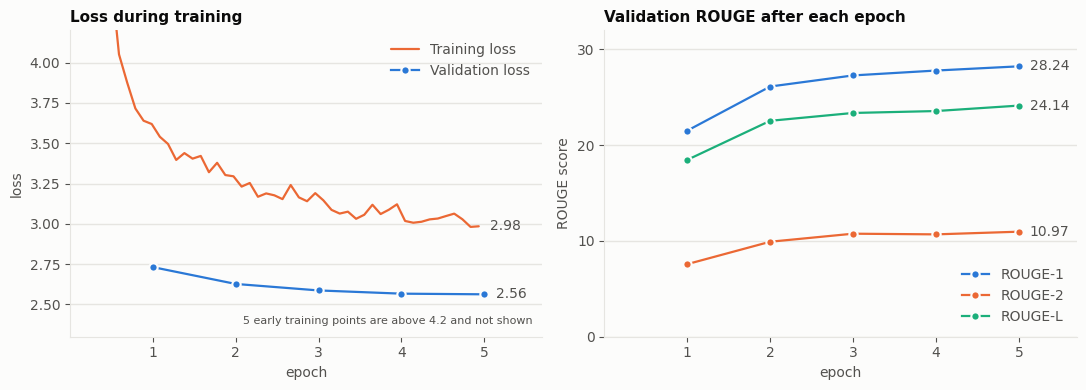

epoch | val loss | rouge1 | rouge2 | rougeL
    1 |    2.732 |  21.52 |   7.58 |  18.47
    2 |    2.627 |  26.13 |   9.92 |  22.55
    3 |    2.587 |  27.29 |  10.76 |  23.37
    4 |    2.567 |  27.80 |  10.69 |  23.57
    5 |    2.563 |  28.24 |  10.97 |  24.14


In [57]:
# 1. Load the training history that was saved together with the best model
import json
import matplotlib.pyplot as plt

with open("banglat5-xlsum-best/trainer_state.json") as f:
    history = json.load(f)["log_history"]

train_log = [(e["epoch"], e["loss"]) for e in history if "loss" in e and "eval_loss" not in e]
val_log = [e for e in history if "eval_loss" in e]
val_epochs = [e["epoch"] for e in val_log]
print(f"Training loss points: {len(train_log)} | validation points: {len(val_log)}")

# 2. Look: a light surface (so the picture looks the same everywhere) and the first three categorical colors
surface, ink, ink_soft, grid = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
blue, orange, aqua = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"font.size": 10, "text.color": ink, "axes.labelcolor": ink_soft,
                     "xtick.color": ink_soft, "ytick.color": ink_soft})

def style_axes(ax, title, ylabel):
    ax.set_facecolor(surface)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", color=ink)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlim(0, 5.7)
    ax.grid(axis="y", color=grid, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(grid)

def end_label(ax, x, y):
    ax.annotate(f"{y:.2f}", (x, y), xytext=(8, 0), textcoords="offset points", va="center", color=ink_soft)

fig, (ax_loss, ax_rouge) = plt.subplots(1, 2, figsize=(11, 4), facecolor=surface)

# 3. Left: loss. Validation loss (blue, one point per epoch) and training loss (orange, every 50 steps)
y_top = 4.2
train_x, train_y = zip(*train_log)
val_loss = [e["eval_loss"] for e in val_log]
ax_loss.plot(train_x, train_y, color=orange, linewidth=1.6, solid_capstyle="round", label="Training loss")
ax_loss.plot(val_epochs, val_loss, color=blue, linewidth=1.6, marker="o", markersize=6,
             markeredgecolor=surface, markeredgewidth=1.5, label="Validation loss", zorder=3)
ax_loss.set_ylim(2.3, y_top)
end_label(ax_loss, val_epochs[-1], val_loss[-1])
end_label(ax_loss, train_x[-1], train_y[-1])
n_hidden = sum(1 for y in train_y if y > y_top)
if n_hidden:
    ax_loss.text(0.98, 0.04, f"{n_hidden} early training points are above {y_top} and not shown",
                 transform=ax_loss.transAxes, ha="right", fontsize=8, color=ink_soft)
style_axes(ax_loss, "Loss during training", "loss")
ax_loss.legend(frameon=False, loc="upper right", labelcolor=ink_soft)

# 4. Right: validation ROUGE after each epoch (three series, fixed color order)
for label, key, color in [("ROUGE-1", "eval_rouge1", blue), ("ROUGE-2", "eval_rouge2", orange), ("ROUGE-L", "eval_rougeL", aqua)]:
    values = [e[key] for e in val_log]
    ax_rouge.plot(val_epochs, values, color=color, linewidth=1.6, marker="o", markersize=6,
                  markeredgecolor=surface, markeredgewidth=1.5, label=label)
    end_label(ax_rouge, val_epochs[-1], values[-1])
ax_rouge.set_ylim(0, 32)
ax_rouge.set_yticks([0, 10, 20, 30])
style_axes(ax_rouge, "Validation ROUGE after each epoch", "ROUGE score")
ax_rouge.legend(frameon=False, loc="lower right", labelcolor=ink_soft)

fig.tight_layout()
plt.show()

# 5. The same numbers as a table
print("epoch | val loss | rouge1 | rouge2 | rougeL")
for e in val_log:
    print(f"{e['epoch']:5.0f} | {e['eval_loss']:8.3f} | {e['eval_rouge1']:6.2f} | {e['eval_rouge2']:6.2f} | {e['eval_rougeL']:6.2f}")